# CM laser and TPC tracks, run 79513: findings (2026-10-23 / 24)

This notebook collects the studies of the last two days in one place: the CM measurement (Part A), TPC-only tracks reconstructed
with ~90 PHGarfield configurations (Part B), the comparison of the two (Part C), and PHGarfield tuned with tracks (Part D).

## Main findings

**CM measurement (Part A)**
1. *Cluster position.* The production centroid (ADC-weighted pads after the hits-per-flash cut) snaps to the pad centre when a row
   has one pad (~18 %); its S-curve is 150–400 µm. A 3-pad centre of gravity on the raw pad sums is flatter (50–100 µm). Every stripe
   also has its own ~100 µm error tied to the pads under it, renewed when the distortion moves the stripe by ≳ 0.3 pad – the
   "stripe jitter" between runs grows with |ΔI| and saturates. It averages out over a module.
2. *Per-module space charge.* After ring means and a translation, the run-to-run change of the module medians is one sector pattern
   proportional to the GEM current, the same per µA in independent pairs inside a fill and across fills (correlation 0.75–0.99).
3. *Per-module static.* One fit of all 14 beam blocks (static + slope × I + per-fill φ-symmetric terms) describes them to 0.09 mrad;
   the static sector pattern at I = 0 is that of the no-beam field-on runs (correlation 0.8–0.9). With the per-cell static and slope,
   the track-like sector sagitta reaches ≈ 100 µm rms, 93 % of sectors within ±200 µm (leave one block out).
4. *The low-R kink* between fills is space charge (linear in I within and between fills); the final correction over-corrects the
   innermost radii at high current; keff ×0.96 at high current removes it.

**Tracks (Part B)** – rDCA_zero = |circle centre| − radius, so **charge-odd = spatial / pointing, charge-even = curvature**.
5. The φ-averaged pointing follows keff (≈ 12 mm per unit of keff scale): the CM keff is right to 1–3 %
   (zero at ×1.01 South / ×0.97 North); production default −0.7 / −1.4 mm, final −0.1 / +0.4 mm.
6. The large φ harmonic of the pointing (2–4 mm) is the same in every pT and η bin: it is the beam offset seen from the TPC
   (d0 = |b| sin(φ − φ_b)), a translation of the TPC tracks relative to (0, 0) (beam at ≈ (−1.4…−1.8, +2.1…+2.4) mm), different for the two sides by
   0.4–0.7 mm and moved by the space-charge correction – not a φ-dependent distortion inside the TPC.
7. Momentum: the high-pT q+/q− yield ratio (1.2–3 GeV) is very sensitive to keff (0.80 at ×1.1 … 1.32 at ×0.8). Expected in p+p
   ≈ 1.05 (π, K ≈ 1, p/p̄ ≈ 1.25); the 0.3–1 GeV bin, insensitive to curvature, reads 1.02–1.05 in all configurations. Default:
   1.06 South (right) / 1.21 North; **final: 0.90 / 0.94 – over-corrected, not an improvement of the momentum scale**; pointing and momentum prefer different keff (0.97–1.01 vs
   0.85–0.95), and every tested knob moves both along the same line – the radial shape in z / the drift-length dependence is what
   remains to be found.
8. Curvature (charge-even) shows sharp sector-boundary dips (1–2 mm) identical in all configurations: module-edge effects that
   PHGarfield does not touch. The module's own `residual_rphi` projects the track to the cluster z (z-model errors leak in); the fit
   residual to the track's own circle is used instead: the corrections remove most of the static-only R shape; the R2/R3-boundary dip
   responds to the frame charge.

**CM ↔ tracks (Part C)**
9. A track model that places the clusters where the track crosses each layer (φ_i = φ0 − q asin(r/2R)) and scales the CM
   distortion with the drift length predicts the change of the tracks for every configuration difference: the φ-averaged pointing
   (scale −1.0…−1.15, the sign of rDCA), its η dependence bin by bin (e.g. 1.28 / 1.35 mm at η 0 to 0.73 / 0.79 mm at η −1), the
   φ shape of the module-gain changes, and the curvature (CM-predicted d(q/pT) vs N+/N−: correlation −0.98).
10. What the CM does not see: a translation of the whole TPC relative to the beam (finding 6), effects near the readout and the
   sector edges. The CM is therefore a quantitative calibration tool for everything that is a distortion inside the TPC; the
   pointing to the beam and the absolute momentum scale need the tracks (or the silicon).

**Tuning with tracks (Part D)**
11. *Module gains fitted with tracks* (one run per module, charge doubled): with ±10 % module changes, the φ structure of pointing,
   curvature and fit residuals drops by 25–30 % (pointing from rDCA_zero with the beam sine removed; the module's rDCA to its own TPC vertex is self-biased and not used). The R1 weights agree with the CM v13 weights (corr. 0.43–0.55); the R2/R3 weights do not.
12. *Frames:* +60 V on one side lowers that side's fit residuals by 20–30 % and leaves the other side alone. Both sides at +90 V give the best
   charge-odd residual. Above +120 V the charge-even residual blows up. The frames barely move the pointing and they lower the high-pT q+/q−.

In [1]:
%matplotlib inline
import sys, os, pickle
sys.path.insert(0, '/home/yoren/bnl/ROOT/install/lib')
import numpy as np, matplotlib.pyplot as plt
from IPython.display import display
import cmpos as cm, scfull as sf, trkana as ta, cmtrk as ct, tgain as tg
plt.rcParams['figure.dpi'] = 55
def show(*figs):
    for f in figs:
        display(f)
    plt.close('all')
HAVE_GB = os.path.exists(f'{ta.HISTS}/trkhists_gb_modsum.root')
HAVE_FR = os.path.exists(f'{ta.HISTS}/trkhists_frame_pp300.root')

# Part A. The CM measurement
## A1. Cluster position: pad response, DNL / S-curve, single-stripe errors
The module centroid snaps to the pad centre for single-pad rows (S-curve 150–400 µm); a 3-pad COG on the raw pad sums is flatter
(50–100 µm). Stripe-level errors (~100 µm) are renewed when the distortion moves a stripe across the pads; they average out over a
module.

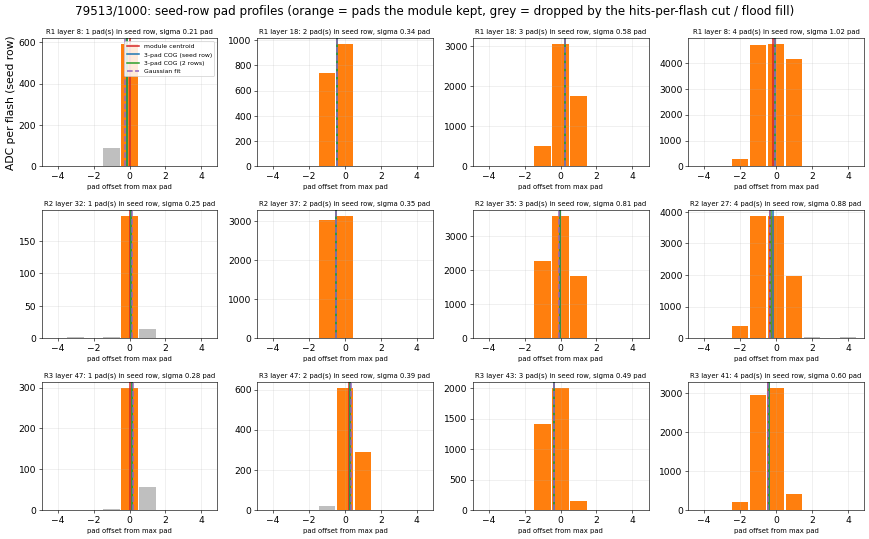

In [2]:
show(cm.fig_pad_profiles(('79513', 1000)))

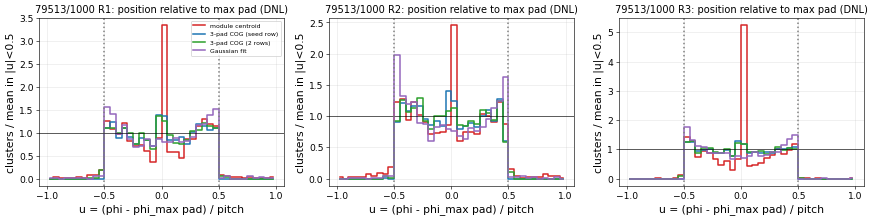

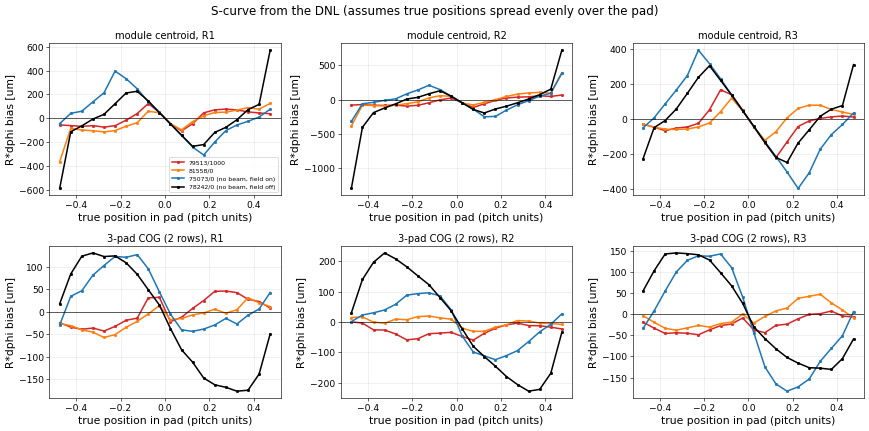

In [3]:
show(cm.fig_dnl(('79513', 1000)), cm.fig_scurve())

single-stripe scatter around its 8 neighbours, robust rms [um], S R1/R2/R3 | N R1/R2/R3
79513/1000
   module centroid                       225  198  213 |  234  135  188
   module centroid, DNL-corrected        186  186  273 |  246  146  179
   3-pad COG (2 rows)                    184  174  131 |  225  157  143
   3-pad COG (2 rows), DNL-corrected     163  173  142 |  213  151  127
81558/0
   module centroid                       290  284  234 |  385  196  210
   module centroid, DNL-corrected        291  286  239 |  408  218  192
   3-pad COG (2 rows)                    263  257  165 |  424  220  176
   3-pad COG (2 rows), DNL-corrected     261  255  164 |  427  231  152
75073/0 (no beam, field on)
   module centroid                       526  435  276 |  486  536  665
   module centroid, DNL-corrected        633  437  341 |  580  617  773
   3-pad COG (2 rows)                    453  376  211 |  463  575  636
   3-pad COG (2 rows), DNL-corrected     448  388  244 |  485  603  658
7

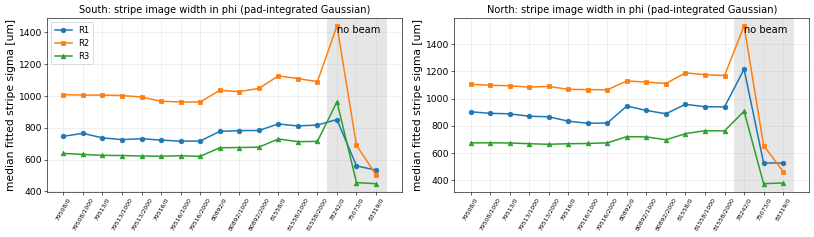

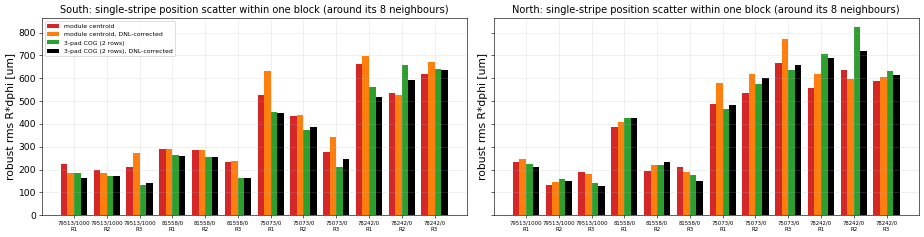

In [4]:
show(cm.fig_sigma(), cm.fig_resolution())

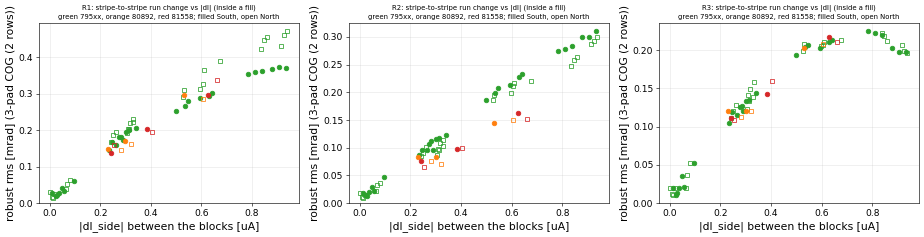

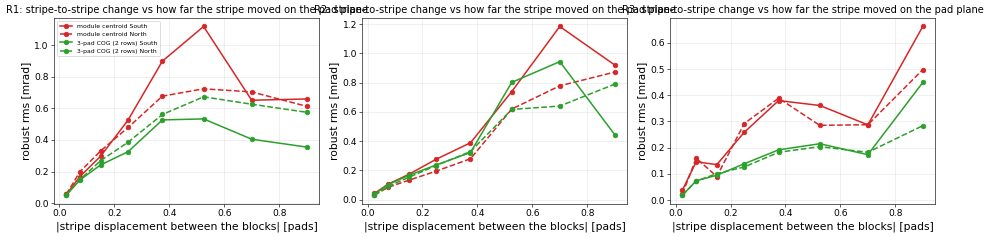

In [5]:
show(cm.fig_jitter_vs_dI(), cm.fig_jitter_vs_shift())

## A2. Per-module space charge (proportional to the GEM current) and per-module static
The sector pattern of the run-to-run change is the same per µA in independent pairs (in-fill and cross-fill): per-module space charge
the maps miss. The static at I = 0 (14-block fit) is the no-beam pattern.

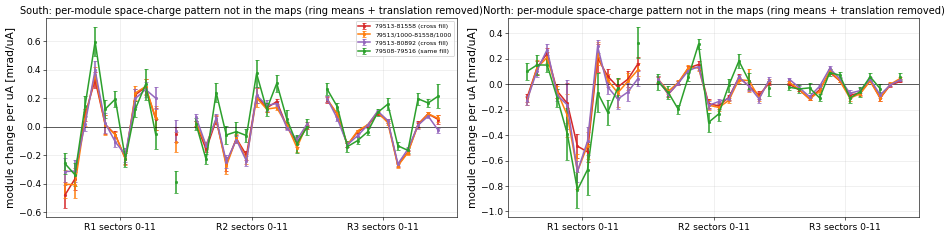

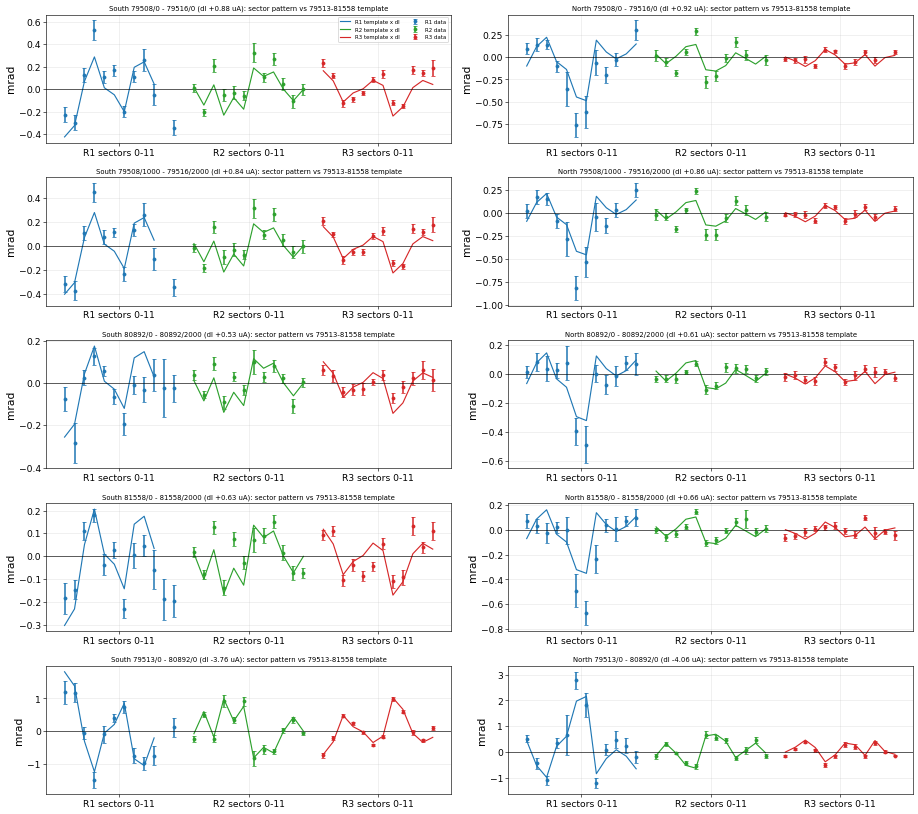

In [6]:
show(cm.fig_pattern_per_uA(), cm.fig_pattern_prediction())

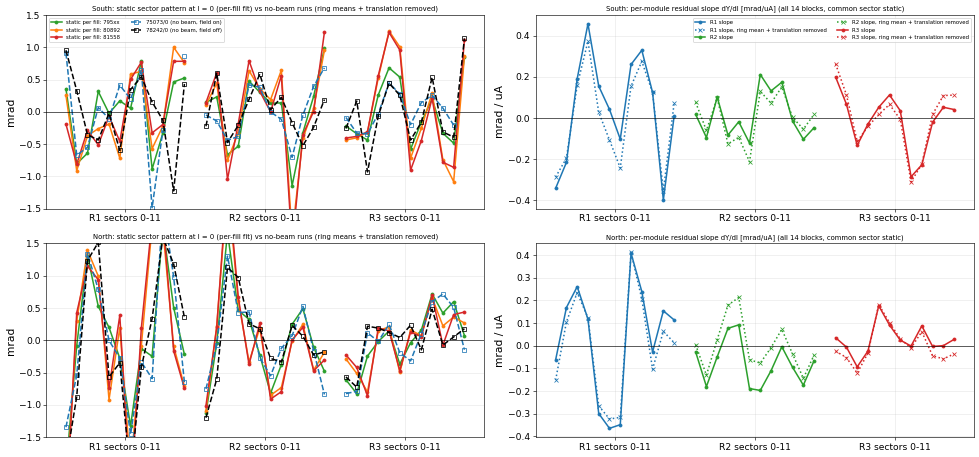

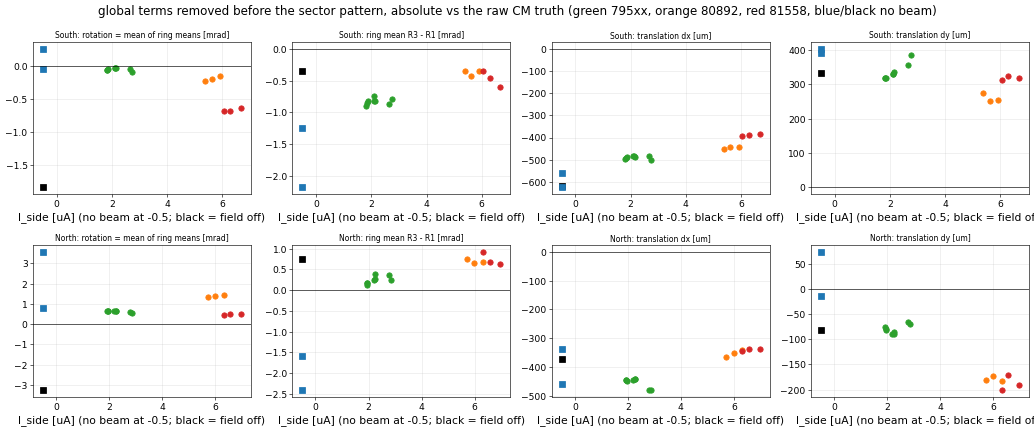

In [7]:
show(cm.fig_static_gain(), cm.fig_global_terms())

South: cell slopes rms 0.227 mrad/uA; after nuisance only 0.229, after module weights 0.139 | delta (charge change) rms 0.17, range -0.26..+0.39
North: cell slopes rms 0.211 mrad/uA; after nuisance only 0.209, after module weights 0.121 | delta (charge change) rms 0.12, range -0.32..+0.28


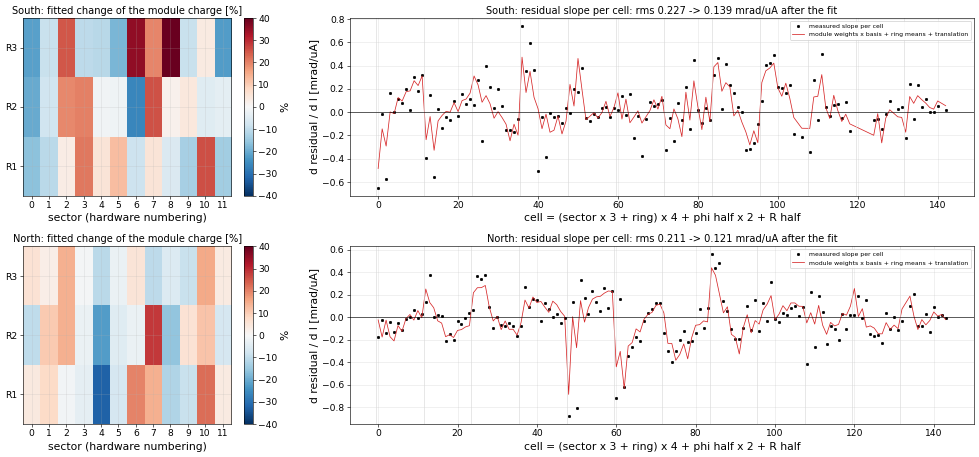

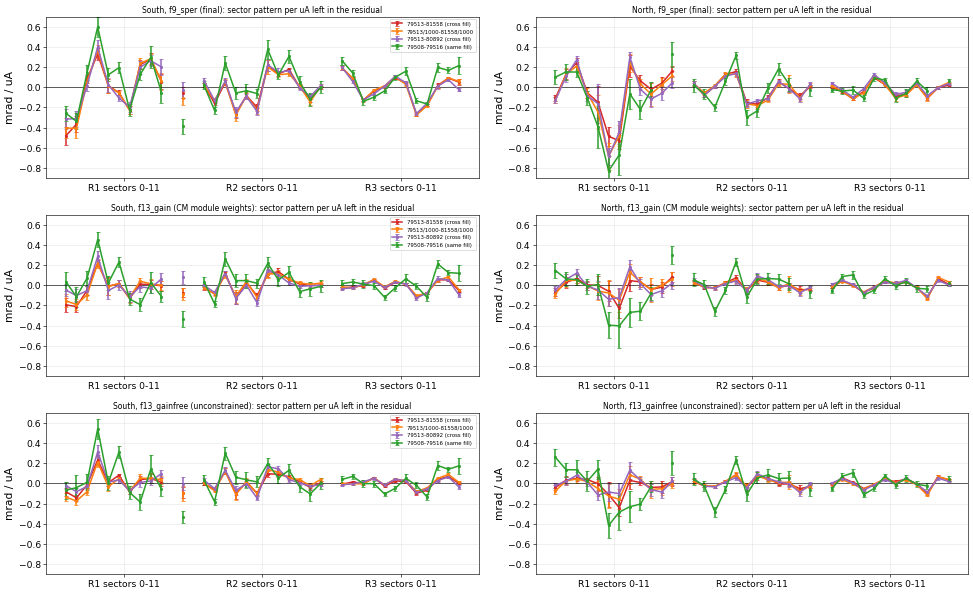

In [8]:
show(cm.fig_gain(), cm.fig_v13_patterns())

track sagitta per sector (cells, 3-pad COG (2 rows)), 14 beam blocks x 12 sectors: rms / worst [um] / within +-200 um
  South as measured                               : rms  1208, worst  3384, within  11%
  South per-cell static removed (A + fill terms)  : rms   889, worst  2748, within  29%
  South static + linear SC removed (full model)   : rms   135, worst  1213, within  93%
  South model fit residual 0.145 mrad per cell
  North as measured                               : rms   831, worst  2353, within  22%
  North per-cell static removed (A + fill terms)  : rms   683, worst  2209, within  31%
  North static + linear SC removed (full model)   : rms    90, worst   463, within  98%
  North model fit residual 0.165 mrad per cell
  South static A(I=0) sector sagitta: rms 732 um | 75073: rms 890 um, corr with A +0.90 | 83319: rms 1521 um, corr with A -0.17
  North static A(I=0) sector sagitta: rms 527 um | 75073: rms 804 um, corr with A +0.81 | 83319: rms 1276 um, corr with A +0.84


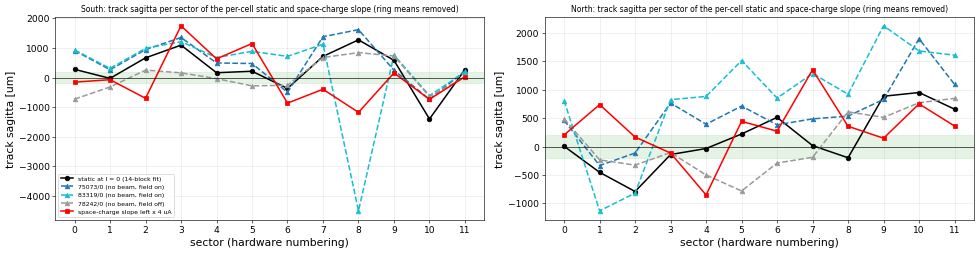

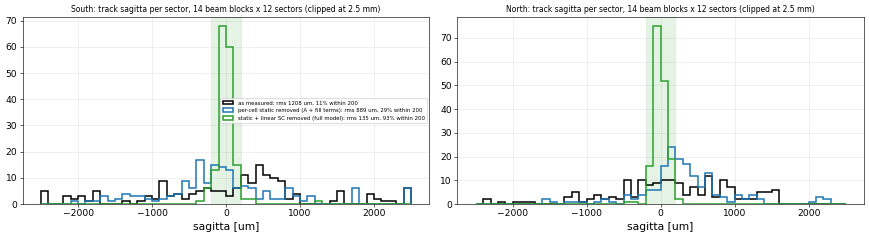

In [9]:
show(cm.fig_static_sectors(), cm.fig_sector_sag_hist())

## A3. The full space-charge study (run − run, corrections only)

Welcome to JupyROOT 6.30/06


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/scqa.py:333: RuntimeWarning: Mean of empty slice
  _c[key] = np.nanmean(P, axis=0) if P else np.full(len(R), np.nan)


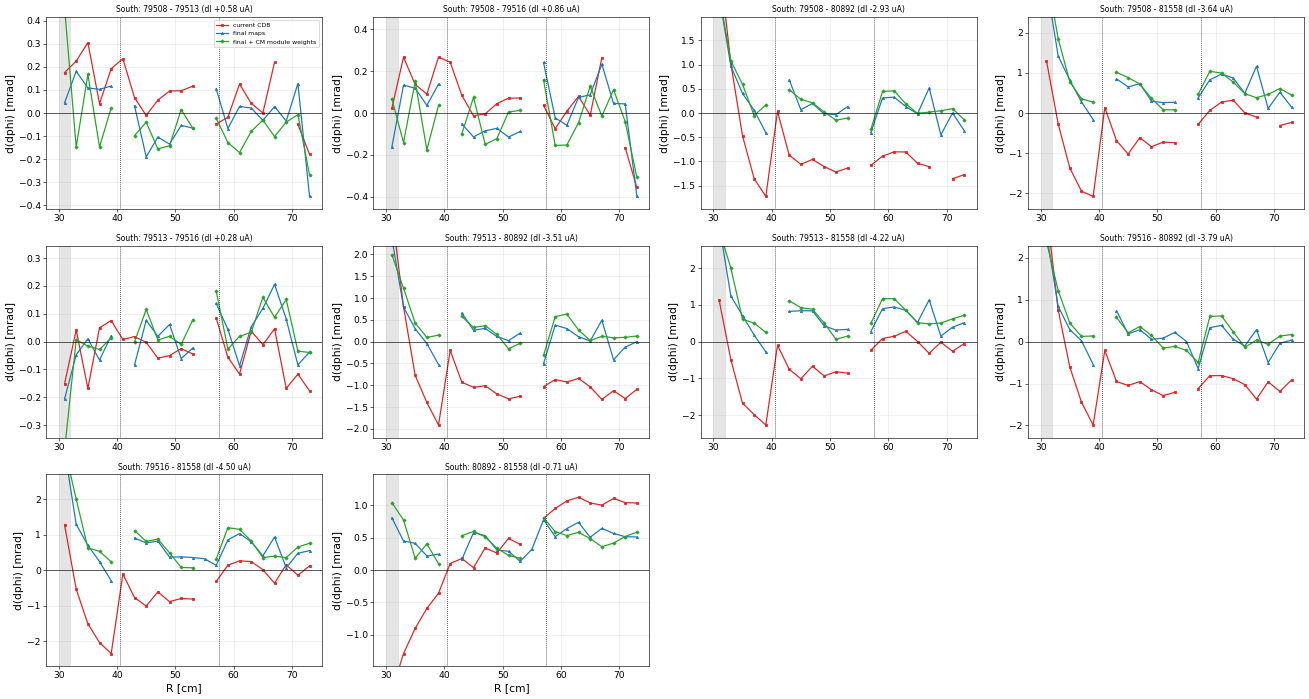

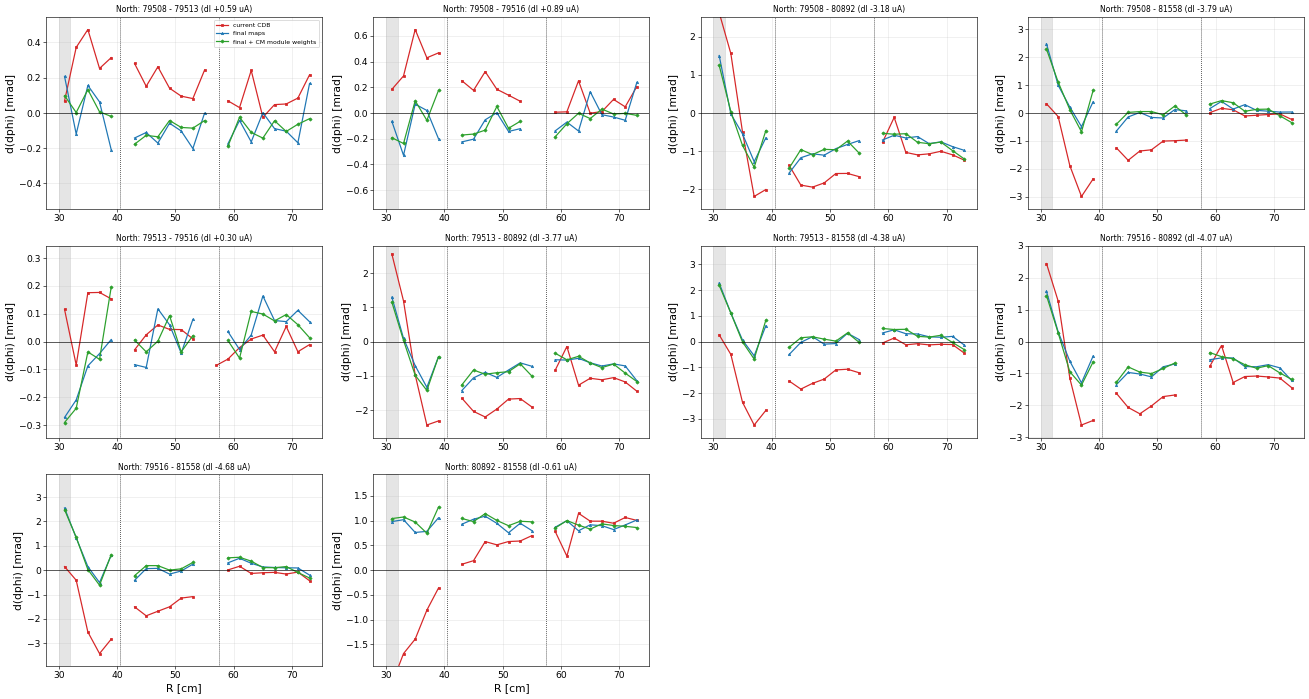

In [10]:
show(sf.fig_run_diffs_corr(0), sf.fig_run_diffs_corr(1))

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/r1check.py:36: RuntimeWarning: Mean of empty slice
  return np.nanmean([prof(T[rb], s, e, keep, weight, edge) for rb in cm.BEAM if rb[0] == run], axis=0)


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/r1check.py:36: RuntimeWarning: Mean of empty slice
  return np.nanmean([prof(T[rb], s, e, keep, weight, edge) for rb in cm.BEAM if rb[0] == run], axis=0)


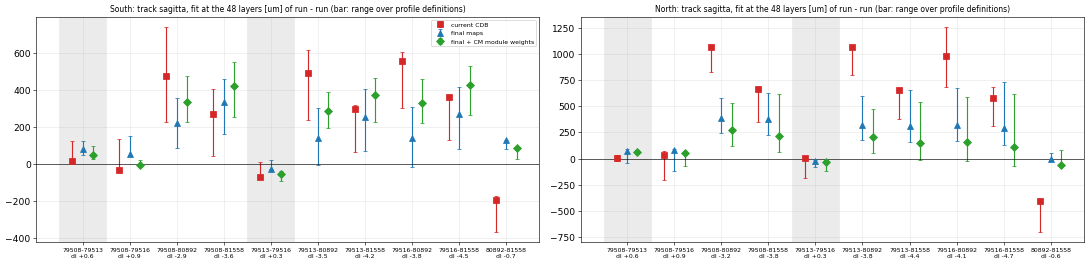

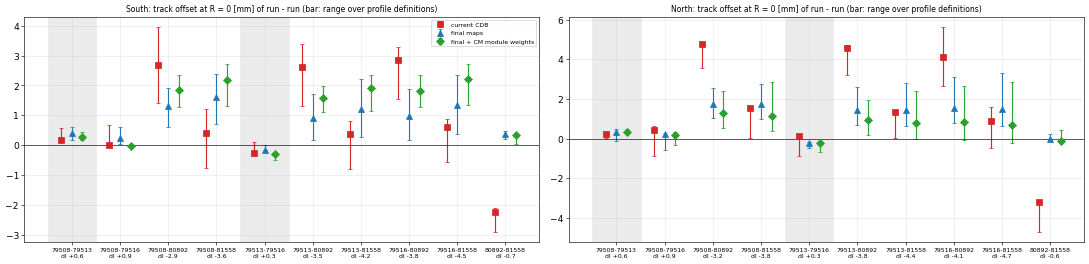

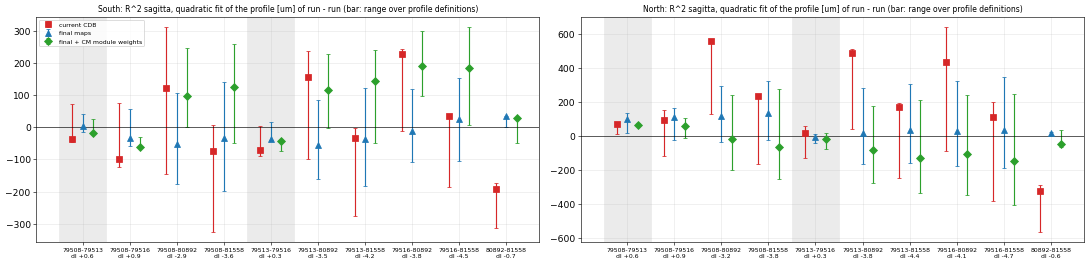

In [11]:
show(sf.fig_observable('tsag'), sf.fig_observable('tdca'), sf.fig_observable('R2'))

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/scfull.py:116: RuntimeWarning: Mean of empty slice
  sq._c[key] = np.nanmean(P, axis=0) if P else np.full(len(R), np.nan)


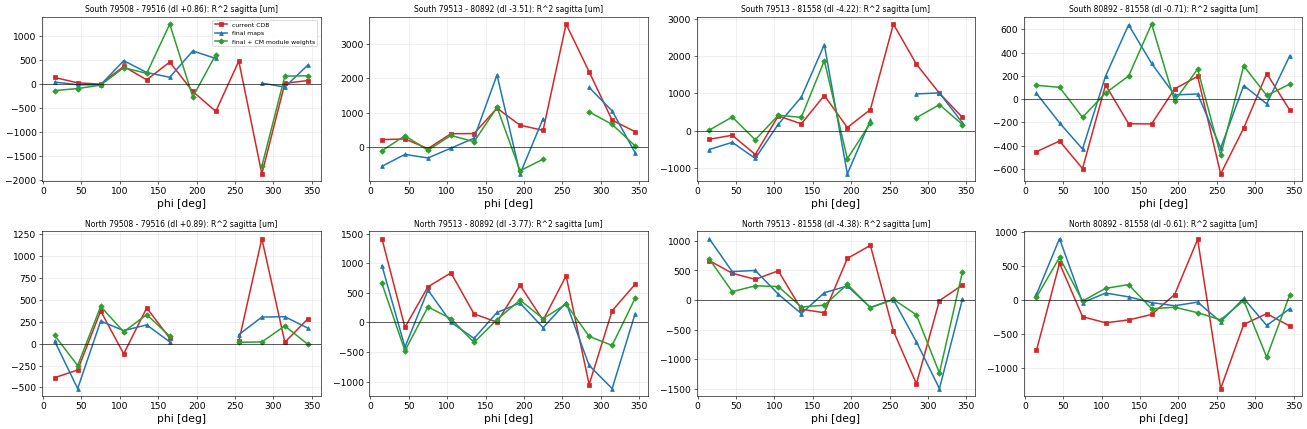

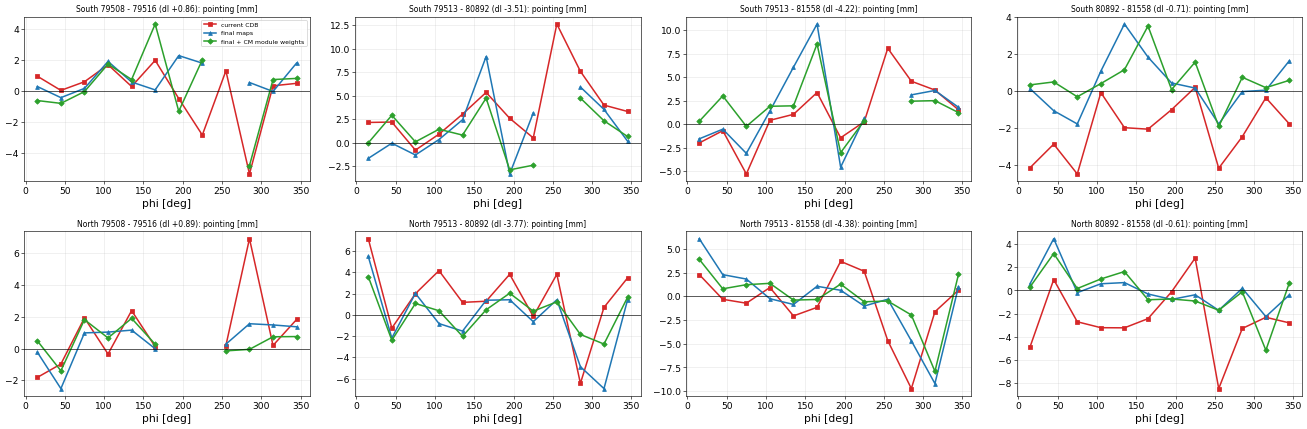

In [12]:
show(sf.fig_sector_observable('R2'), sf.fig_sector_observable('pointing'))

# Part B. TPC-only tracks of 79513 with PHGarfield configurations
Selection: ntpc_clusters > 30, pT > 0.2, |η| < 1.1, |rDCA_zero| < 3 cm, fitted, |pca_z| < 10 cm, quality < 20, |zDCA| < 2 cm,
dE/dx < 400; per side and charge. rDCA_zero = |circle centre| − radius: **charge-odd = spatial / pointing, charge-even = curvature**.
Note on conventions: |c| − R = q·d0, where d0 is the angular-momentum-signed DCA (TpcHadronReco `dca_xy`). In d0 the pointing error
is the **mean** of q+ and q− and the charge-dependent (curvature-type) part is the **difference**: the same information with the labels swapped.

In [13]:
rows = ta.table(['default', 'final', 'static', 'final_k090', 'final_k110', 'gain', 'shape_a18_k100', 'shape_r1092_k100', 'frameSp60', 'frameNp60', 'frame_pp090'])

South: rDCA charge-odd (q+ - q-)/2 mean and first-harmonic amplitude, charge-even amplitude [mm]; pT-slope ratio s+/s-: mean, rms vs phi, rms vs eta; cluster rphi residual vs R: charge-odd and charge-even rms [um]
  config                       ntrk   odd<rDCA> [mm]          odd amp         even amp      N+/N- 1.2-3      N+/N- 0.3-1   slope ratio <> res odd rms [um]     res even rms
  default                     49080           -0.674            2.667            0.080            1.057            1.036            0.977            159.9            126.8
  final                       49494           -0.066            3.810            0.191            0.901            1.038            1.024            157.6             87.8
  static                      49014           -4.285            0.920            0.341            5.656            1.027            0.687            169.7            263.0
  final_k090                  49696           -1.377            3.593            0.124            

## B1. References: production default (CDB-like), final (CM-tuned), static only
rDCA_zero two ways: to (0,0), and with the first φ harmonic (the beam offset, d0 = |b| sin(φ − φ_b)) removed, φ-average kept.
(The module's rDCA to its own TPC vertex is not used: the vertex is built from the same tracks, so it is self-biased.)

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/trkana.py:516: RuntimeWarning: invalid value encountered in divide
  return a / b, ETAC


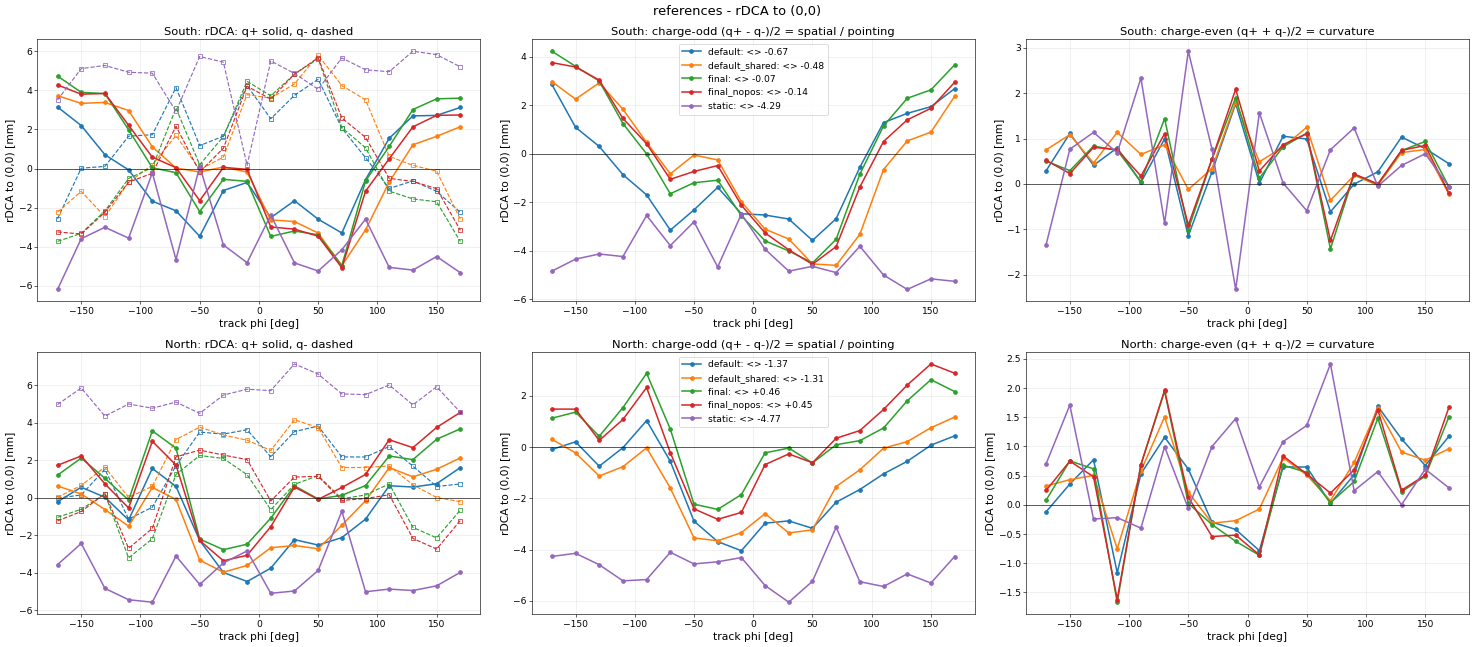

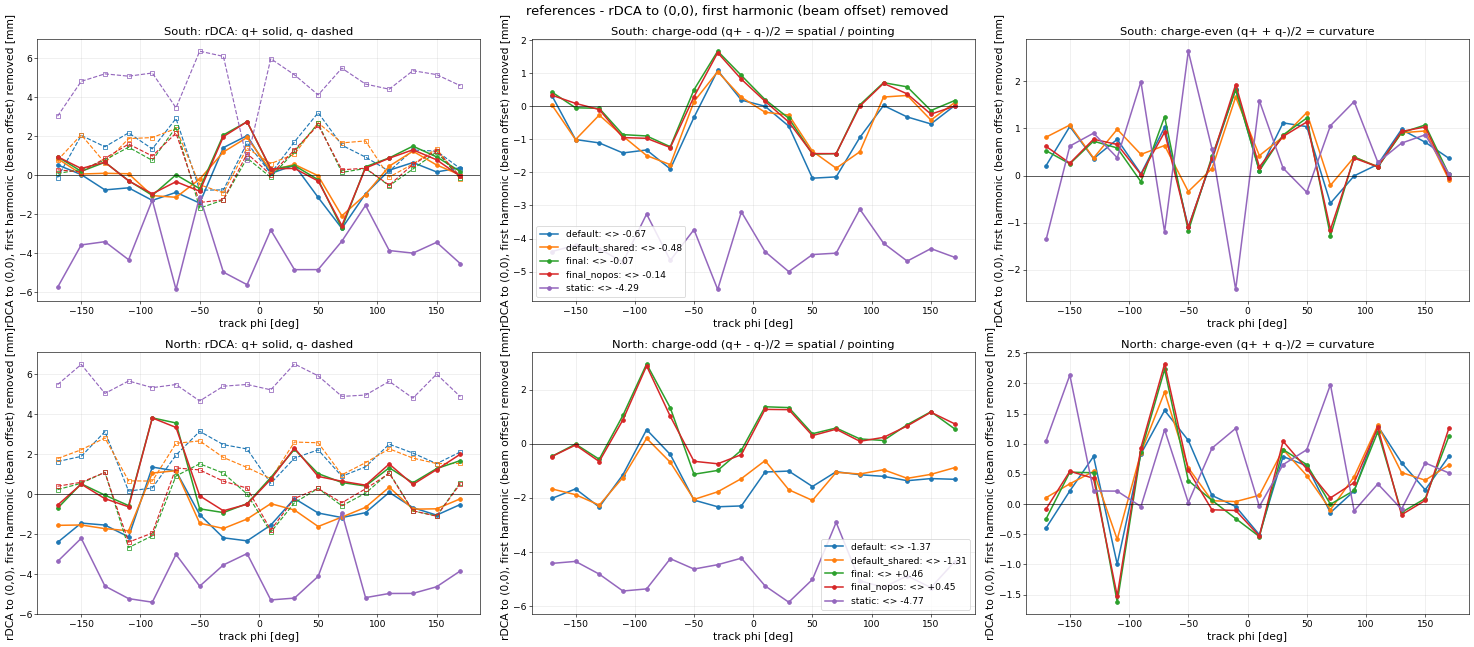

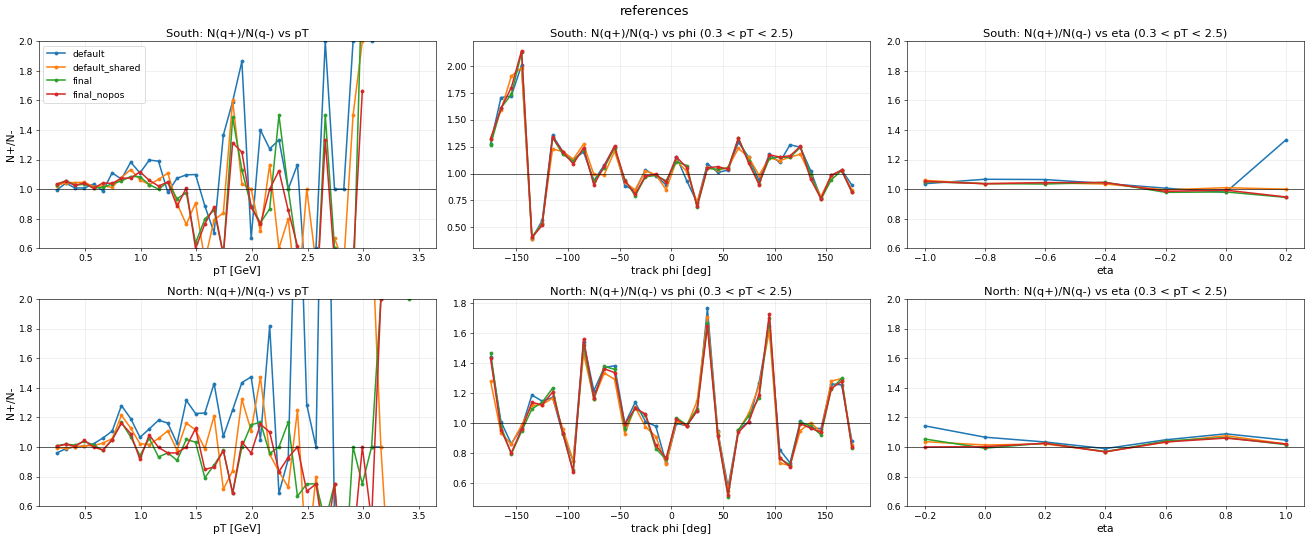

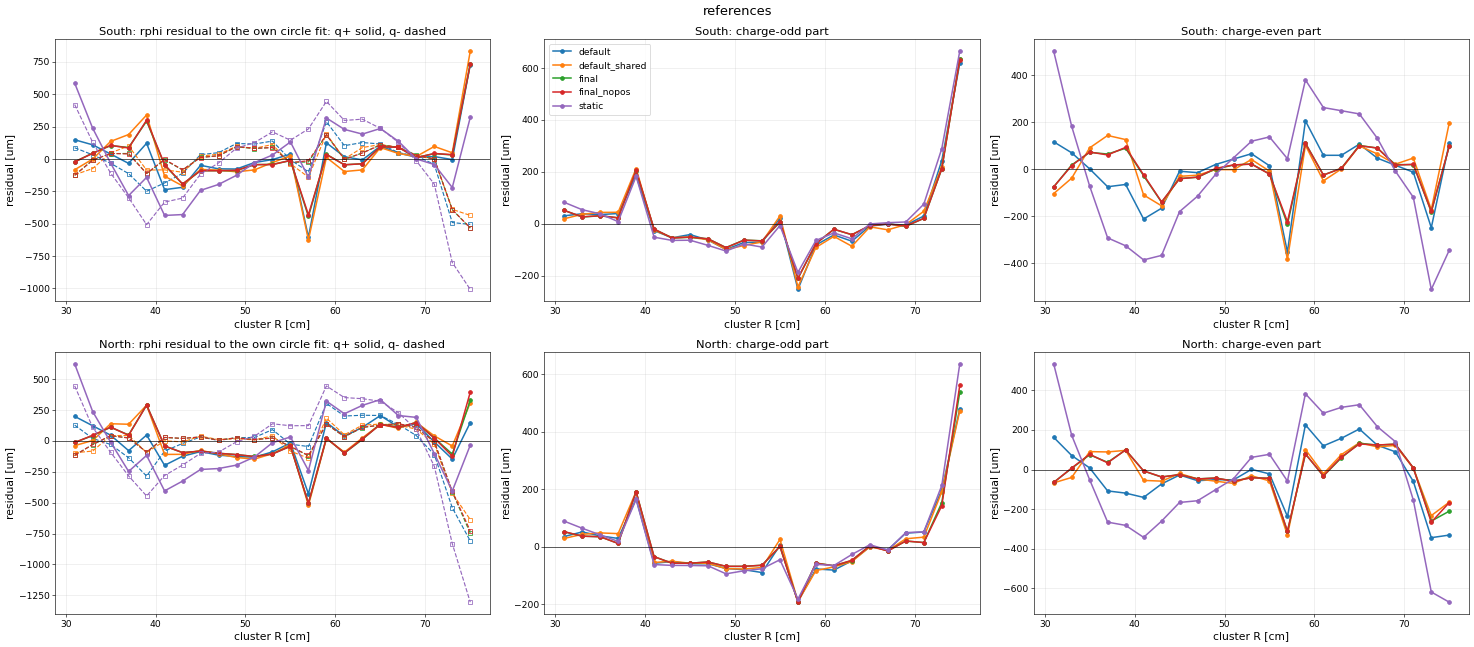

In [14]:
G = ta.GROUPS['references']
show(ta.fig_dca_big(G, 'references'), ta.fig_dca_big(G, 'references', 'nosine'), ta.fig_yield_ratio([t for t in G if t != 'static'], 'references'), ta.fig_resid(G, 'references'))

## B2. keff: the only knob that moves pointing and momentum strongly – and it moves both together

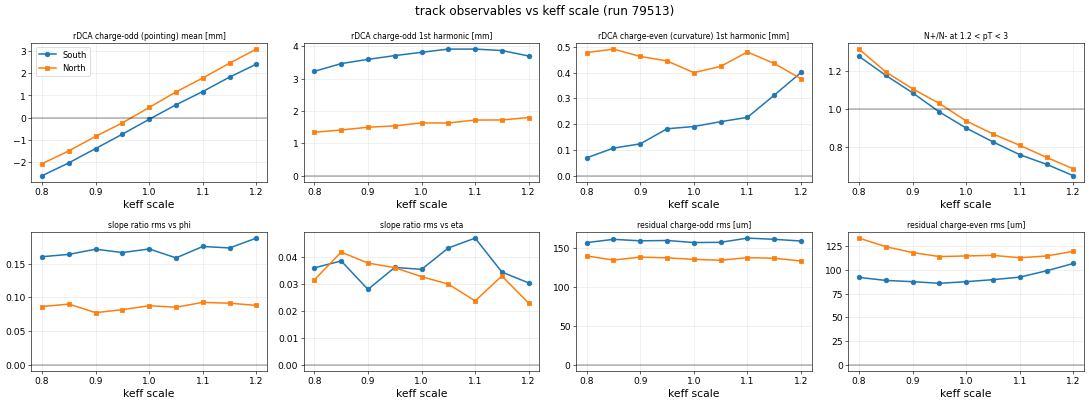

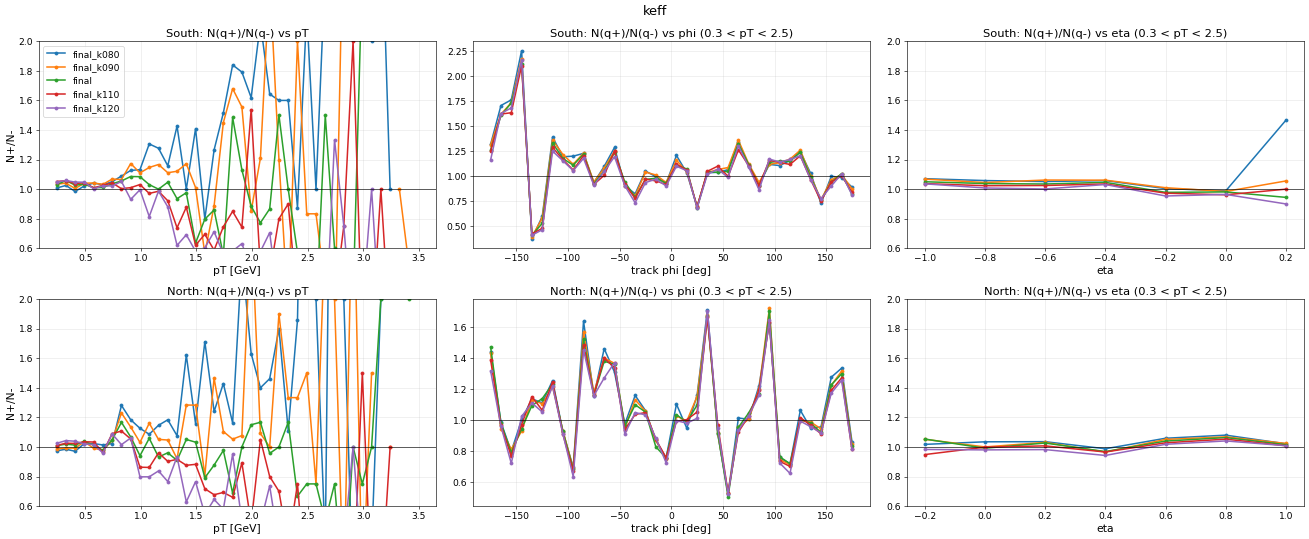

In [15]:
show(ta.fig_scan('keff scale'), ta.fig_yield_ratio(ta.GROUPS['keff'], 'keff'))

## B3. Frames: the only static knob that improves the fit residuals (+60…+90 V)

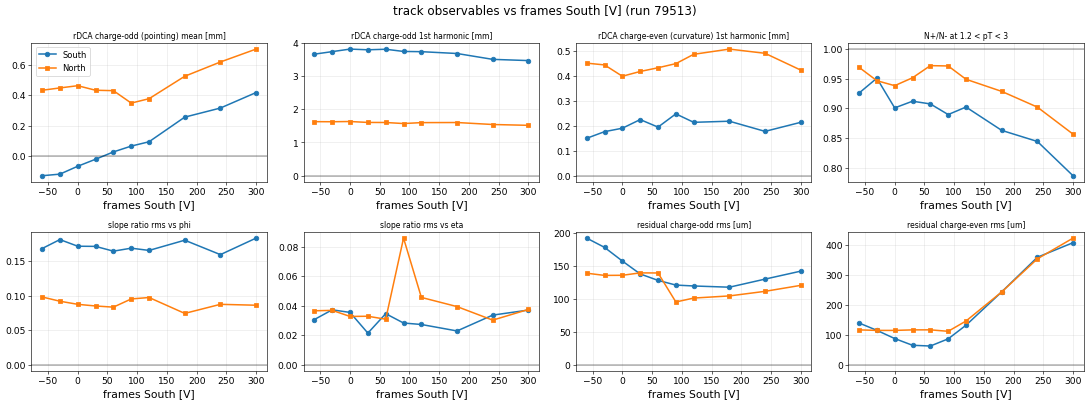

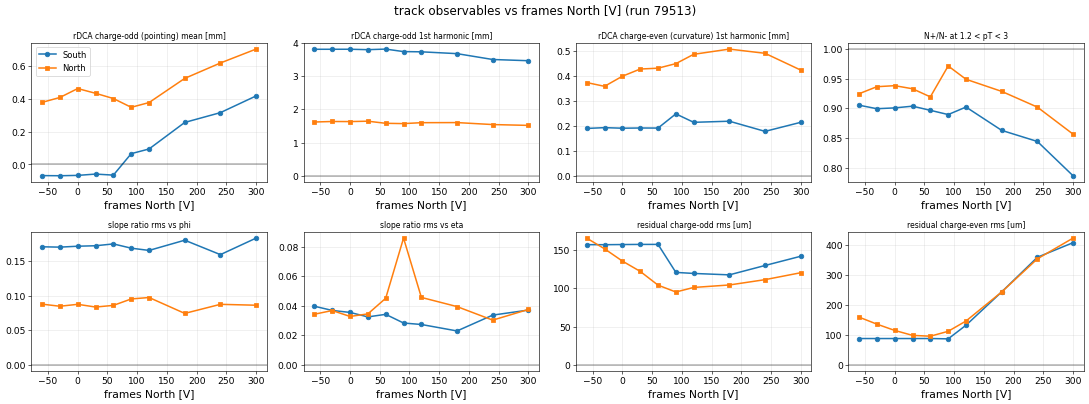

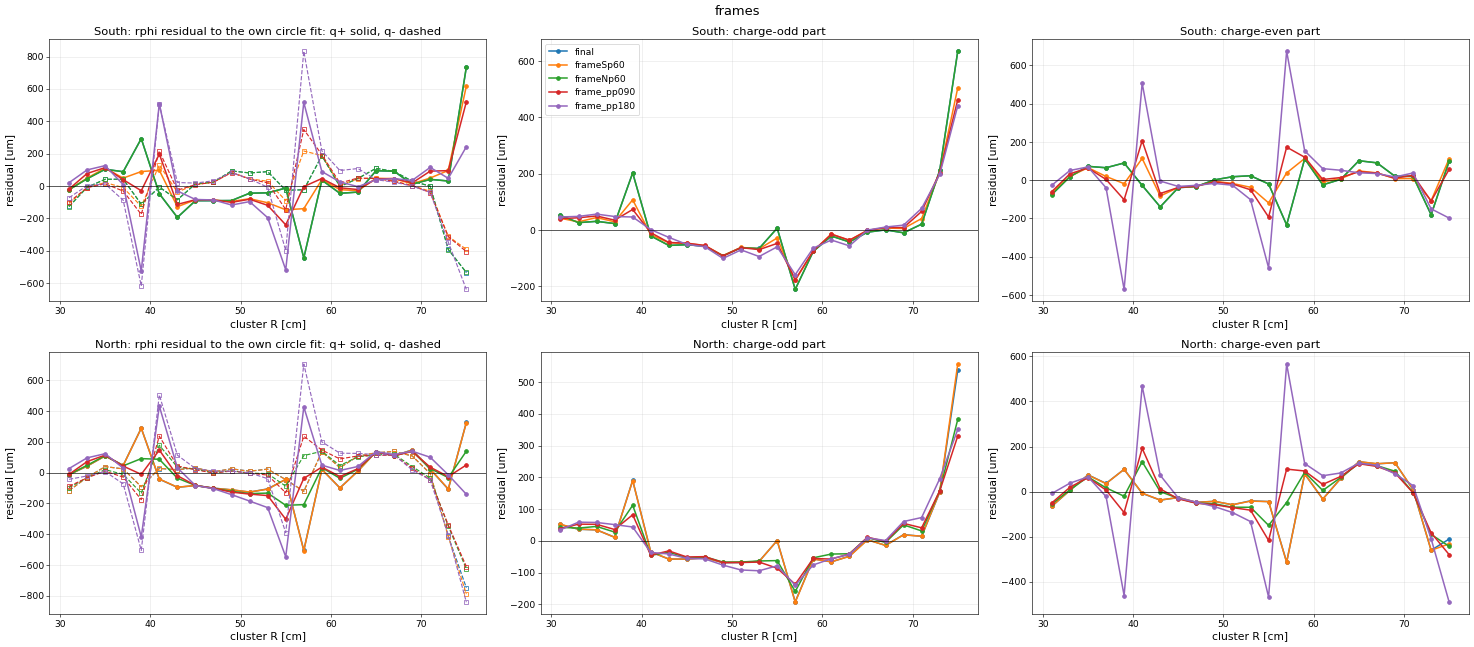

In [16]:
show(ta.fig_scan('frames South [V]'), ta.fig_scan('frames North [V]'), ta.fig_resid(['final', 'frameSp60', 'frameNp60', 'frame_pp090', 'frame_pp180'], 'frames'))

## B4. Knobs that did not help (numbers only): module gains v13, map shapes (α 1.6–1.8, r0), R1 weight, IFC, OFC, magnet / B / gas
They shift pointing and N+/N− along the same line as keff (Part C), and leave the φ structure and the residuals unchanged within a few %.

In [17]:
T = []
for g in ('module gains (v13)', 'map shapes (v14)', 'R1 weight (v14)', 'IFC South', 'IFC North', 'magnet / B / gas'):
    T += [t for t in ta.GROUPS[g] if t not in T]
_ = ta.table(T)

South: rDCA charge-odd (q+ - q-)/2 mean and first-harmonic amplitude, charge-even amplitude [mm]; pT-slope ratio s+/s-: mean, rms vs phi, rms vs eta; cluster rphi residual vs R: charge-odd and charge-even rms [um]
  config                       ntrk   odd<rDCA> [mm]          odd amp         even amp      N+/N- 1.2-3      N+/N- 0.3-1   slope ratio <> res odd rms [um]     res even rms
  final                       49494           -0.066            3.810            0.191            0.901            1.038            1.024            157.6             87.8
  gain                        49410           -0.216            3.298            0.093            0.904            1.038            1.017            156.9             86.1
  gain_half                   49428           -0.138            3.586            0.172            0.906            1.040            1.028            157.3             87.1
  gain_free                   49461           -1.593            3.203            0.070            

## B5. pT and η bins: pointing does not depend on pT; the φ harmonic is the same in every pT and η bin (beam offset)

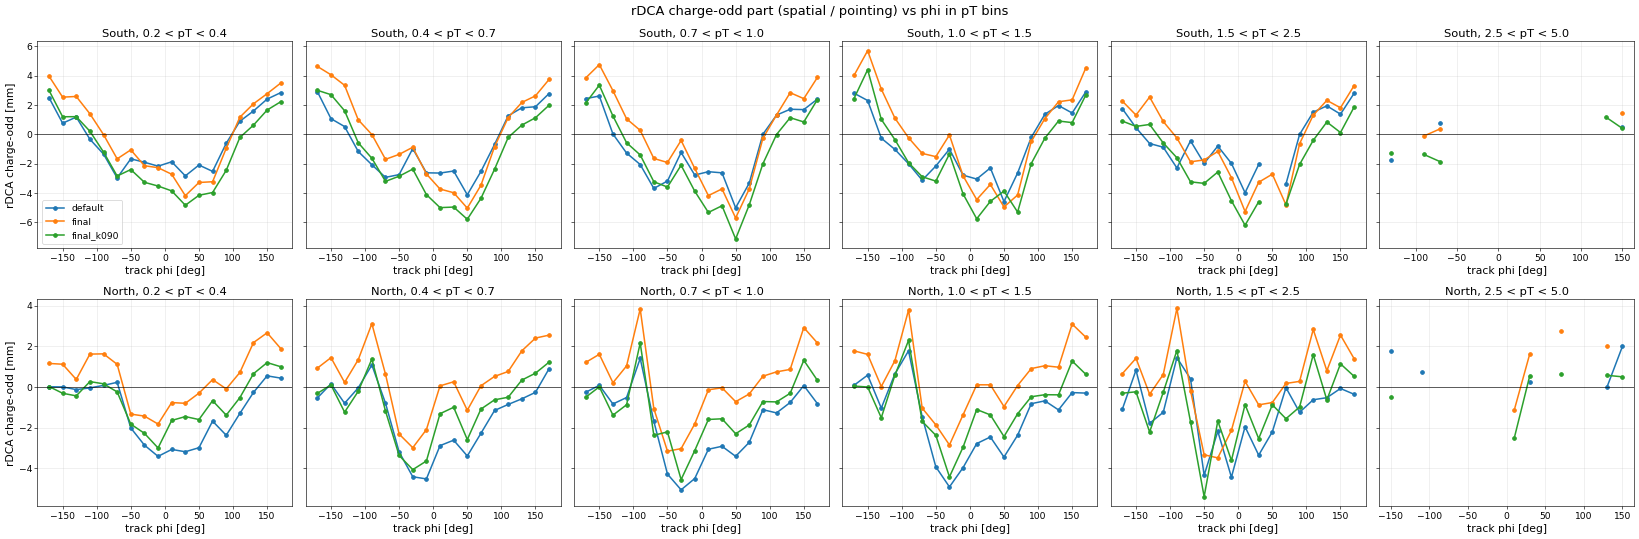

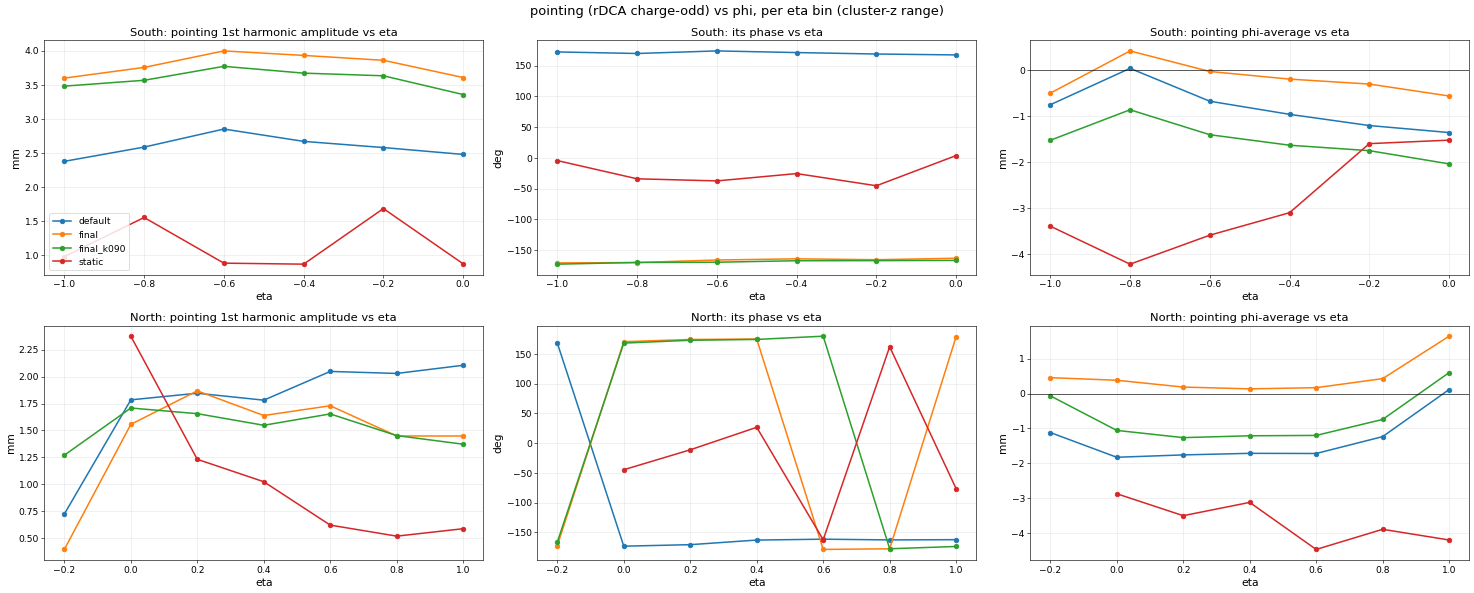

In [18]:
G = ['default', 'final', 'final_k090']
show(ta.fig_dca_ptbins(G, 'odd', 'phi'), ta.fig_eta_harm(G + ['static']))

# Part C. CM ↔ tracks
**Model**: a track (φ0, q, pT, η) has its clusters at the 48 layer radii r_i, at φ_i = φ0 − q·asin(r_i / 2R_curv) (measured on the
tracks, ratio 1.01) and z_i = r_i·sinh η; each cluster moves by r_i·Δφ_CM(r_i, φ_i)·(L − |z_i|)/L; a parabola fit over the layers
gives the pointing shift and the curvature change. **Configuration differences** (same CM clusters, exact) test the model; the
**absolute** CM residual tests what the CM sees.

In [19]:
rows_c = ct.compare_diffs()
T = ct.split_table(rows_c)

pointing change X - final: phi-averaged mean (predicted / measured, mm) and the phi shape (correlation, predicted and
measured rms after removing the mean per pT bin); curvature: predicted d(q/pT) and measured change of N+/N-
South
  static             mean +12.288 / -3.855 | shape corr -0.72, rms 0.531 / 3.675 | dq/pT -153.11e-3, dN+/N- +4.755
  gain               mean -0.184 / -0.163 | shape corr -0.66, rms 0.735 / 0.842 | dq/pT  +4.88e-3, dN+/N- +0.004
  gain_half          mean -0.092 / -0.073 | shape corr -0.70, rms 0.368 / 0.410 | dq/pT  +2.44e-3, dN+/N- +0.005
  gain_free          mean +1.120 / -1.512 | shape corr -0.63, rms 0.714 / 1.006 | dq/pT -10.56e-3, dN+/N- +0.176
  shape_a16_k094     mean +0.964 / -1.062 | shape corr -0.23, rms 0.043 / 0.419 | dq/pT -14.69e-3, dN+/N- +0.166
  shape_a16_k100     mean +0.237 / -0.297 | shape corr -0.07, rms 0.014 / 0.197 | dq/pT  -5.81e-3, dN+/N- +0.070
  shape_a16_k106     mean -0.491 / +0.491 | shape corr -0.14, rms 0.021 / 0.189 | dq/pT 

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/cmtrk.py:279: RuntimeWarning: Mean of empty slice
  Ms = Mm - np.nanmean(Mm, axis=1, keepdims=True)
/home/yoren/.local/lib/python3.10/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/yoren/.local/lib/python3.10/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


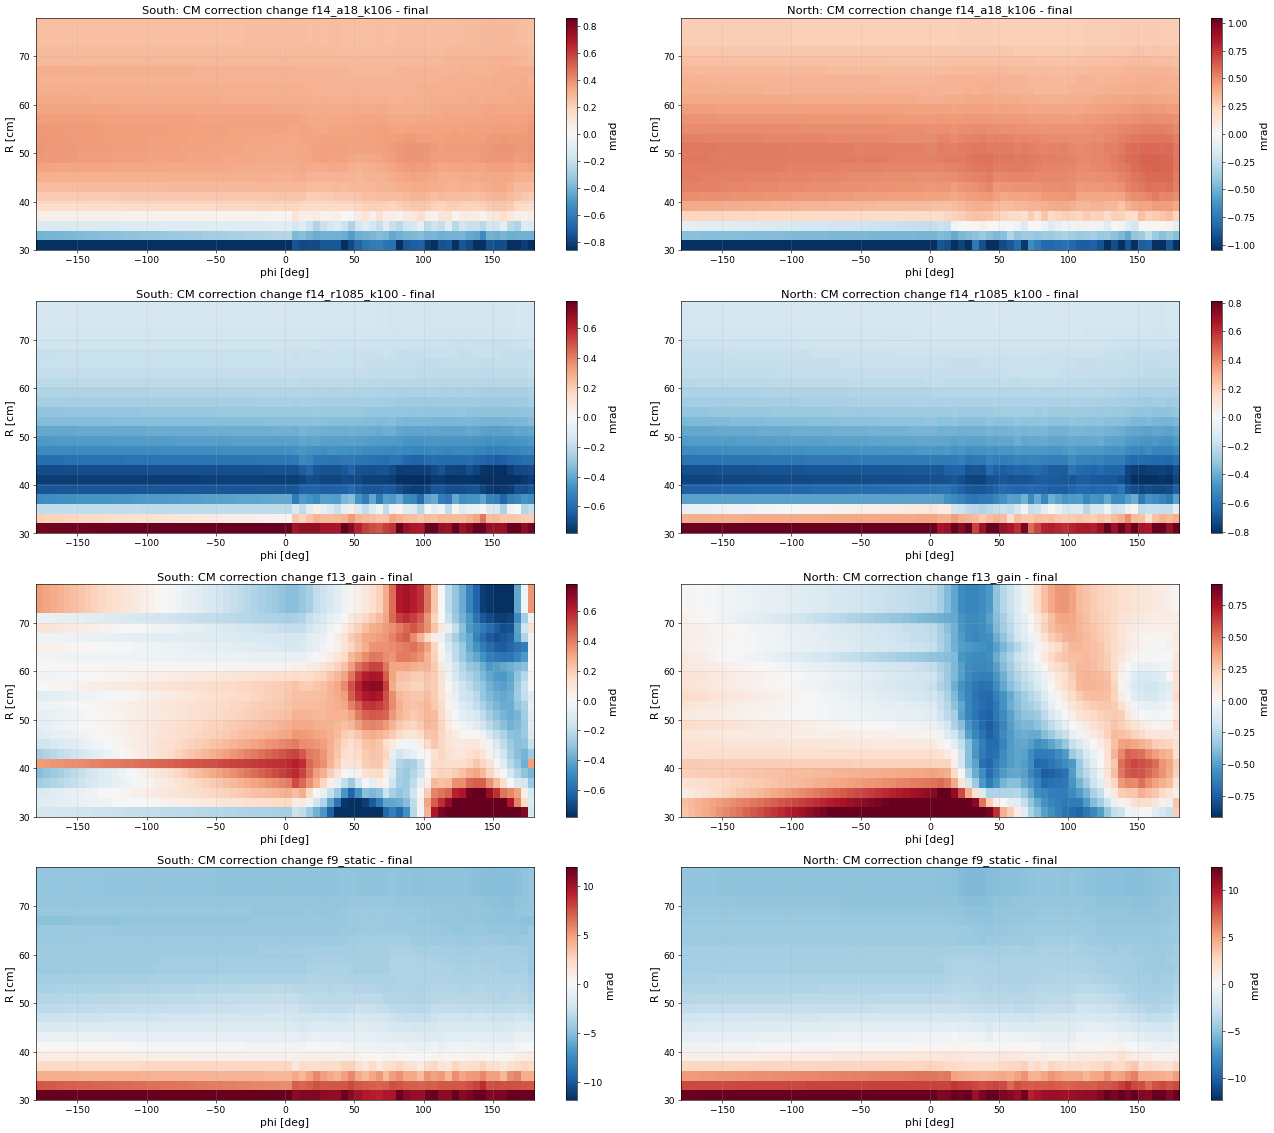

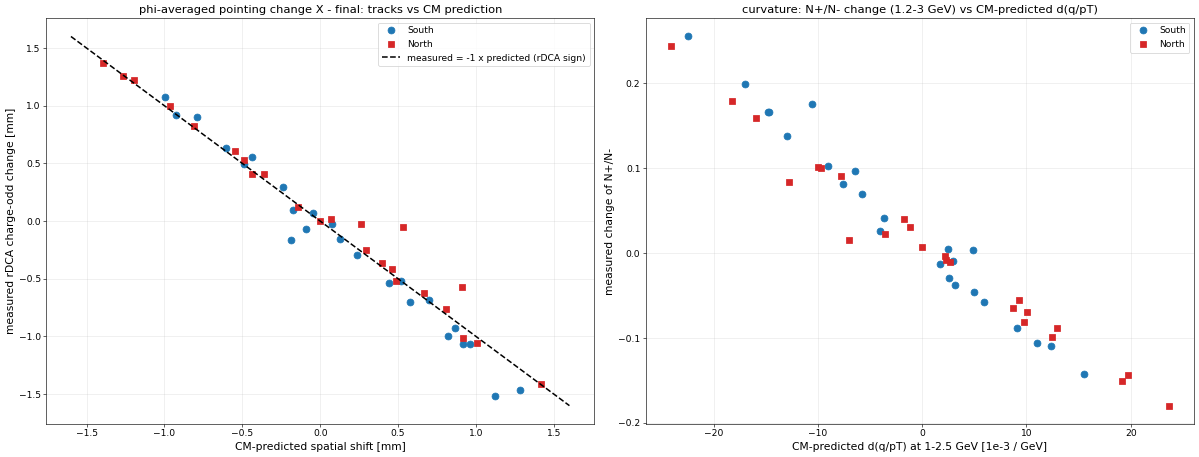

In [20]:
show(ct.fig_cm_maps(), ct.fig_mean_scatter(T))

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/cmtrk.py:366: RuntimeWarning: Mean of empty slice
  pz = np.array([-np.nanmean([propagate(M, s, p0, q, 1.0, ee)[0] for p0 in PHI18 for q in (1, -1)]) for ee in e])
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/cmtrk.py:367: RuntimeWarning: Mean of empty slice
  pn = np.array([-np.nanmean([propagate(M, s, p0, q, 1.0, ee, zscale=False)[0] for p0 in PHI18 for q in (1, -1)]) for ee in e])


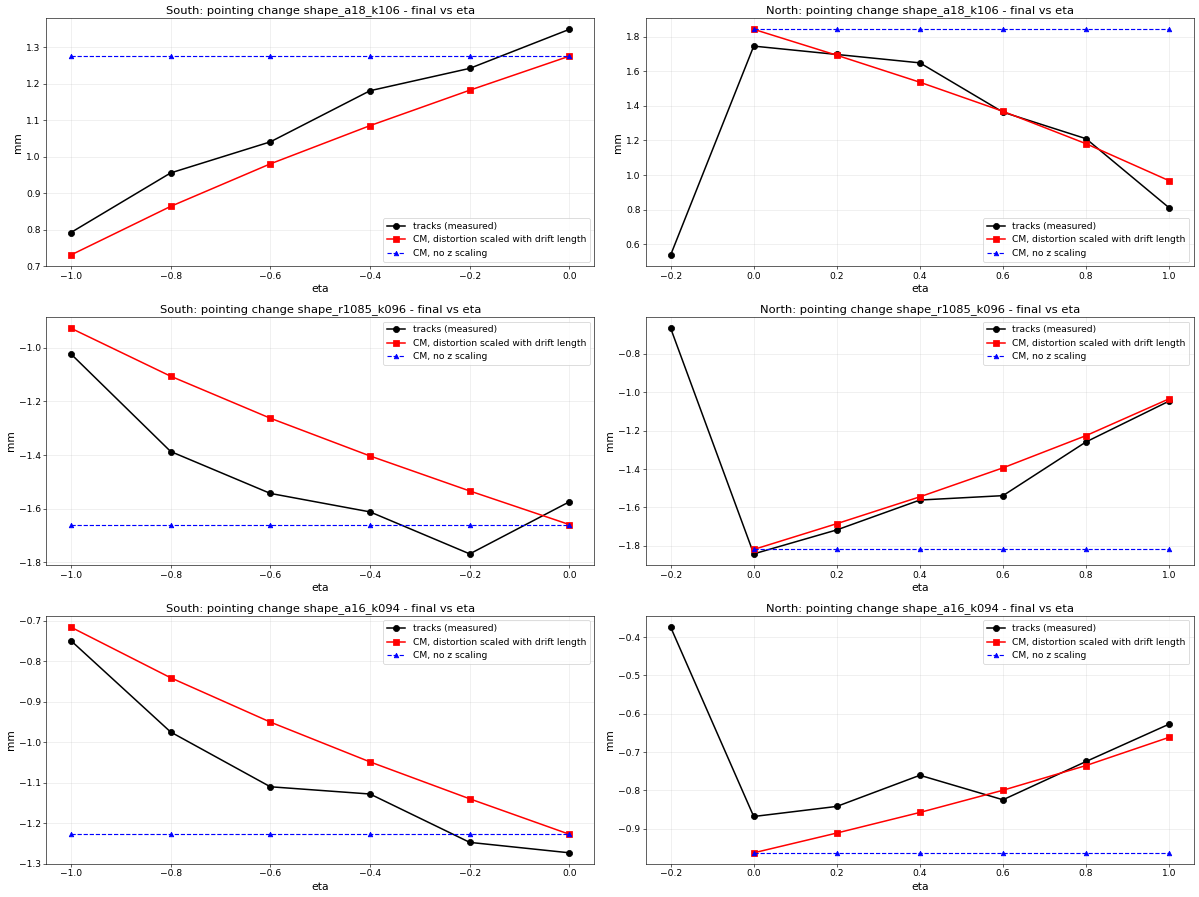

In [21]:
show(ct.fig_eta_validation())

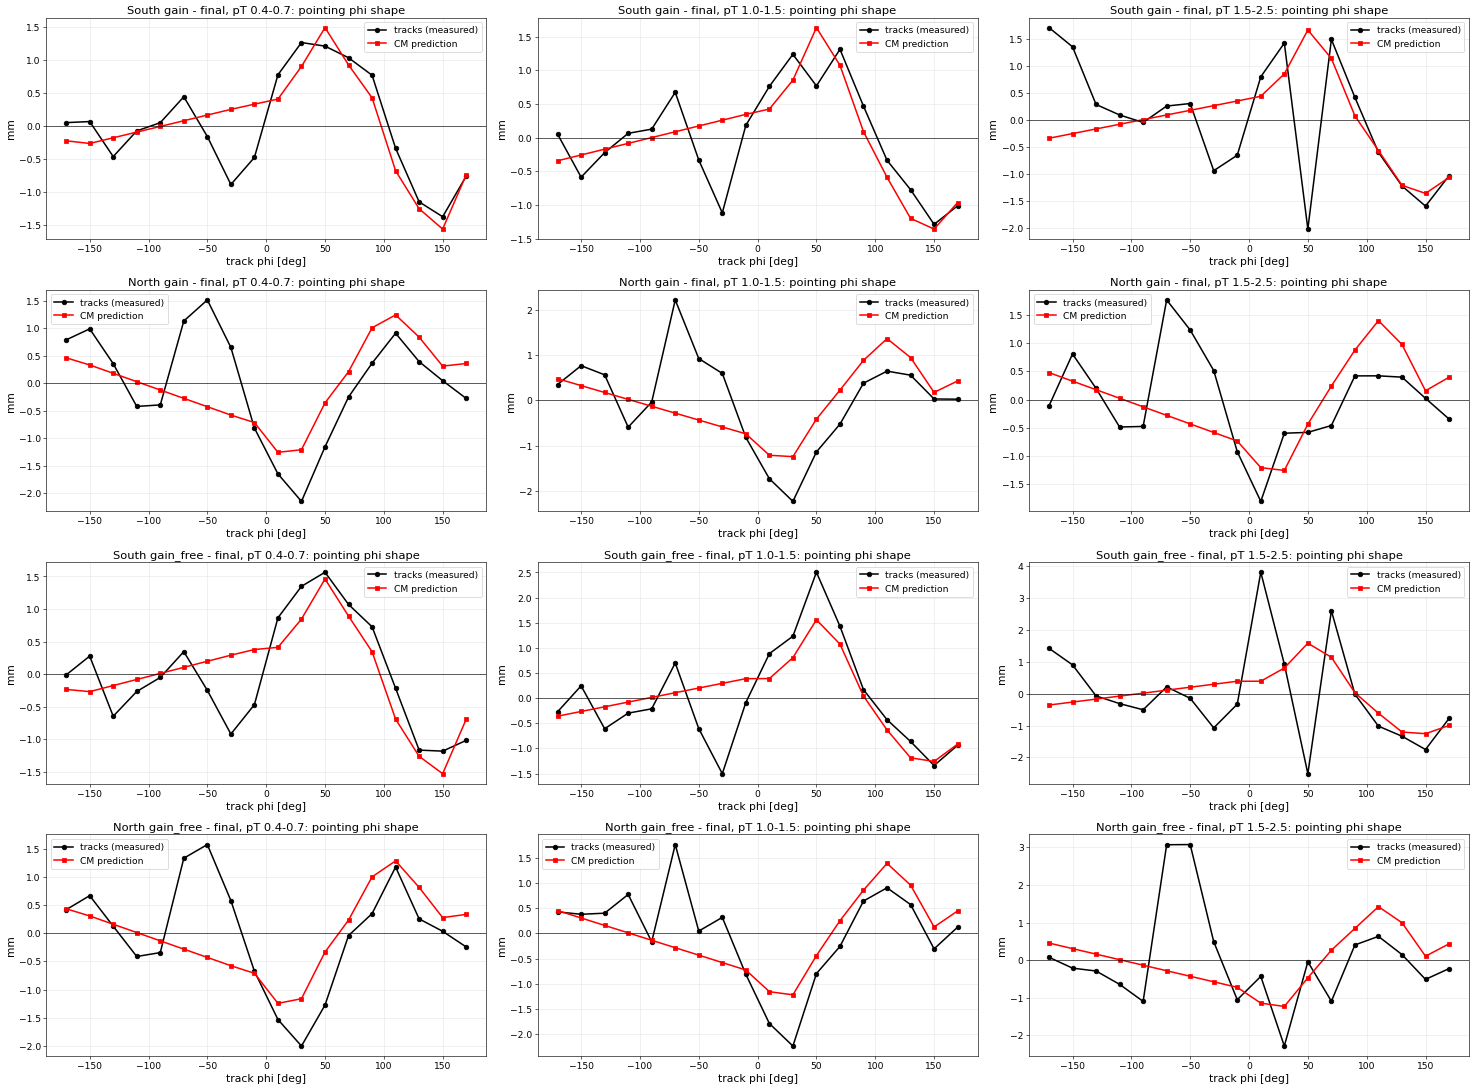

In [22]:
show(ct.fig_shape(rows_c))

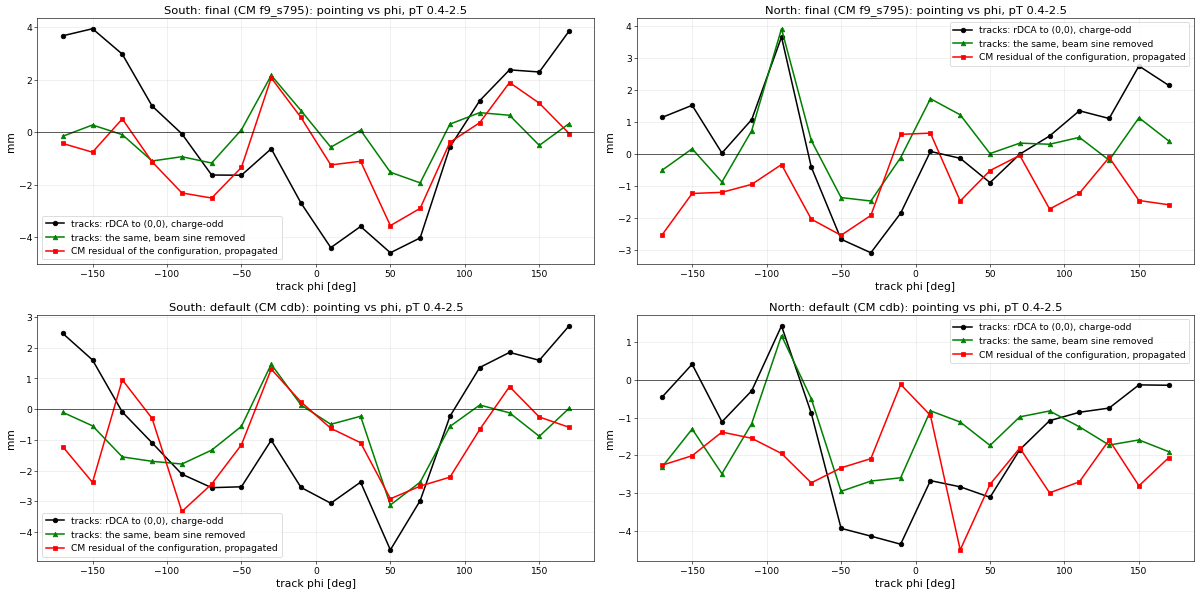

In [23]:
show(ct.fig_absolute())

# Part D. Tuning PHGarfield with tracks: per-module gains

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/tgain.py:38: RuntimeWarning: Mean of empty slice
  out['point_v'] = P - np.nanmean(P, axis=1, keepdims=True)
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/tgain.py:39: RuntimeWarning: Mean of empty slice
  out['curv'] = C - np.nanmean(C, axis=1, keepdims=True)


South fit on point_v+curv+resmap (ridge 0.3): delta rms 0.12, range -0.26..+0.47 | point_v: 0.933 -> 0.652 | curv: 0.902 -> 0.647 | resmap: 99.002 -> 68.476 | closure modsum-final: point_v 0.000 curv 0.000 resmap 0.000


South fit on point_v (ridge 0.3): delta rms 0.11, range -0.35..+0.37 | point_v: 0.933 -> 0.396 | curv: 0.902 -> 0.643 | resmap: 99.002 -> 104.858 | closure modsum-final: point_v 0.000 curv 0.000 resmap 0.000


South fit on curv (ridge 0.3): delta rms 0.11, range -0.14..+0.37 | point_v: 0.933 -> 0.621 | curv: 0.902 -> 0.491 | resmap: 99.002 -> 104.498 | closure modsum-final: point_v 0.000 curv 0.000 resmap 0.000


South fit on resmap (ridge 0.3): delta rms 0.14, range -0.34..+0.42 | point_v: 0.933 -> 0.953 | curv: 0.902 -> 0.802 | resmap: 99.002 -> 63.989 | closure modsum-final: point_v 0.000 curv 0.000 resmap 0.000


South fit on point_v+curv (ridge 0.3): delta rms 0.11, range -0.26..+0.47 | point_v: 0.933 -> 0.428 | curv: 0.902 -> 0.531 | resmap: 99.002 -> 105.557 | closure modsum-final: point_v 0.000 curv 0.000 resmap 0.000


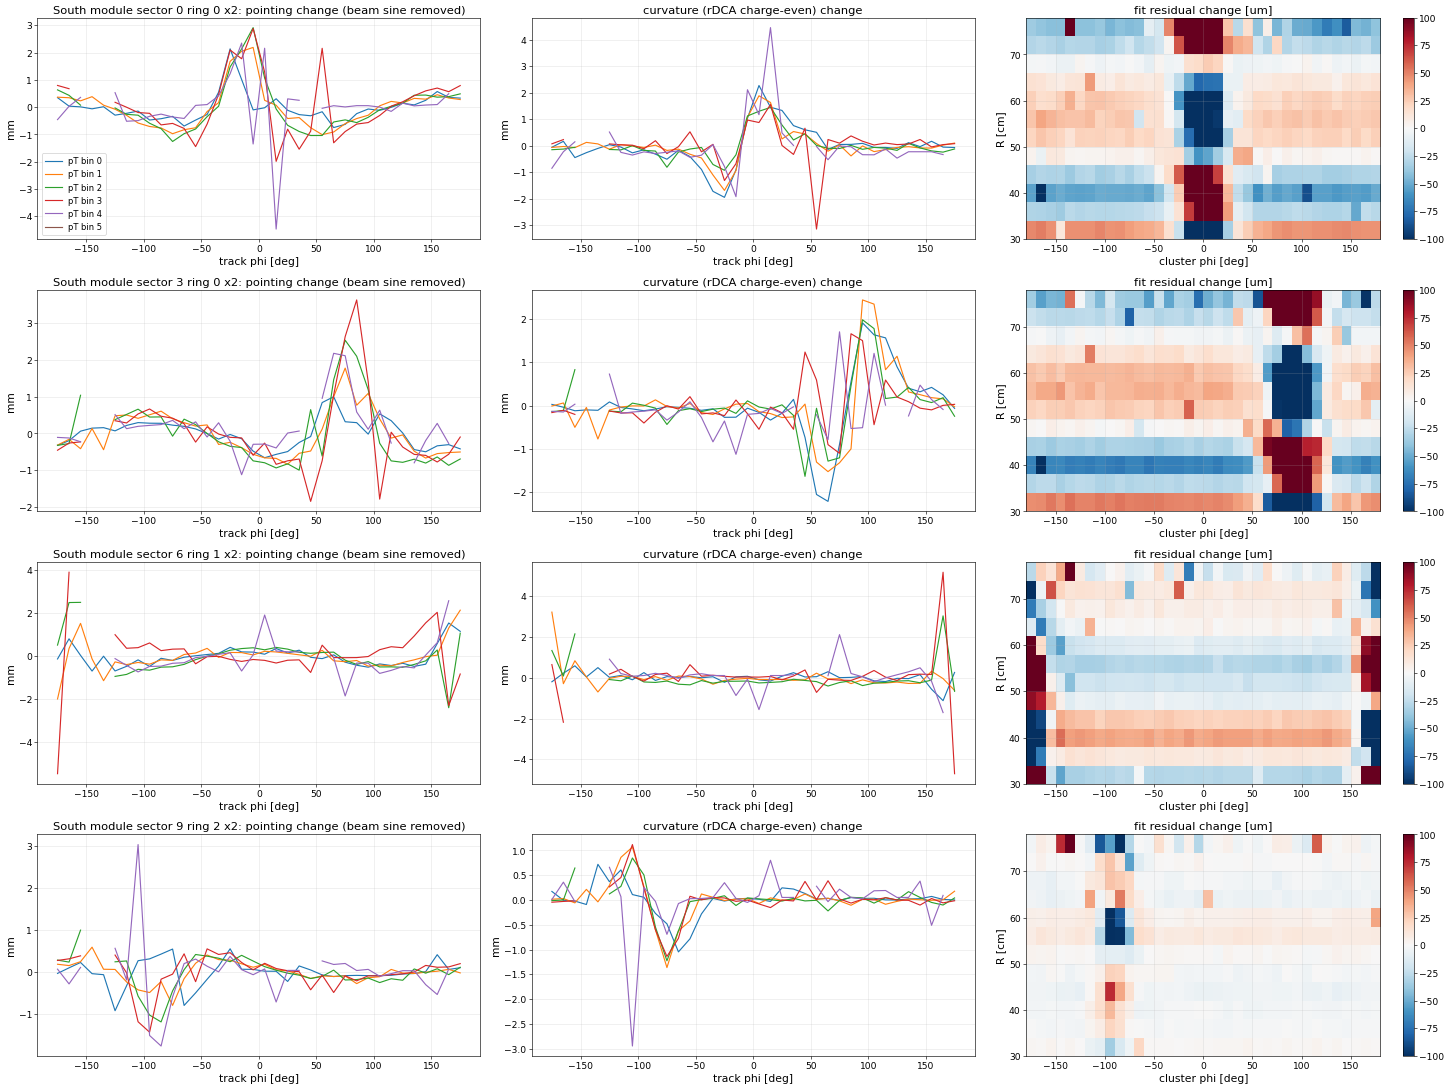

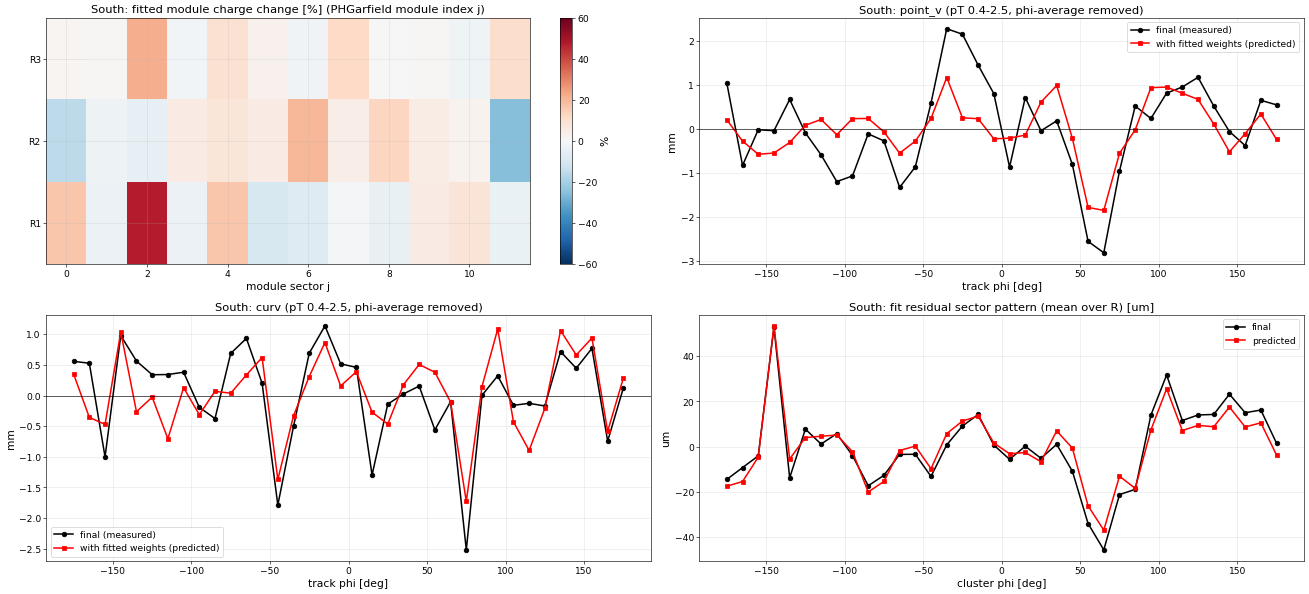

North fit on point_v+curv+resmap (ridge 0.3): delta rms 0.11, range -0.20..+0.35 | point_v: 1.200 -> 0.783 | curv: 0.864 -> 0.647 | resmap: 89.370 -> 78.099 | closure modsum-final: point_v 0.000 curv 0.000 resmap 0.000


North fit on point_v (ridge 0.3): delta rms 0.16, range -0.18..+0.64 | point_v: 1.200 -> 0.589 | curv: 0.864 -> 0.650 | resmap: 89.370 -> 102.913 | closure modsum-final: point_v 0.000 curv 0.000 resmap 0.000


North fit on curv (ridge 0.3): delta rms 0.14, range -0.25..+0.39 | point_v: 1.200 -> 0.819 | curv: 0.864 -> 0.526 | resmap: 89.370 -> 109.312 | closure modsum-final: point_v 0.000 curv 0.000 resmap 0.000


North fit on resmap (ridge 0.3): delta rms 0.12, range -0.25..+0.32 | point_v: 1.200 -> 1.200 | curv: 0.864 -> 0.889 | resmap: 89.370 -> 72.903 | closure modsum-final: point_v 0.000 curv 0.000 resmap 0.000


North fit on point_v+curv (ridge 0.3): delta rms 0.14, range -0.21..+0.57 | point_v: 1.200 -> 0.643 | curv: 0.864 -> 0.570 | resmap: 89.370 -> 104.215 | closure modsum-final: point_v 0.000 curv 0.000 resmap 0.000


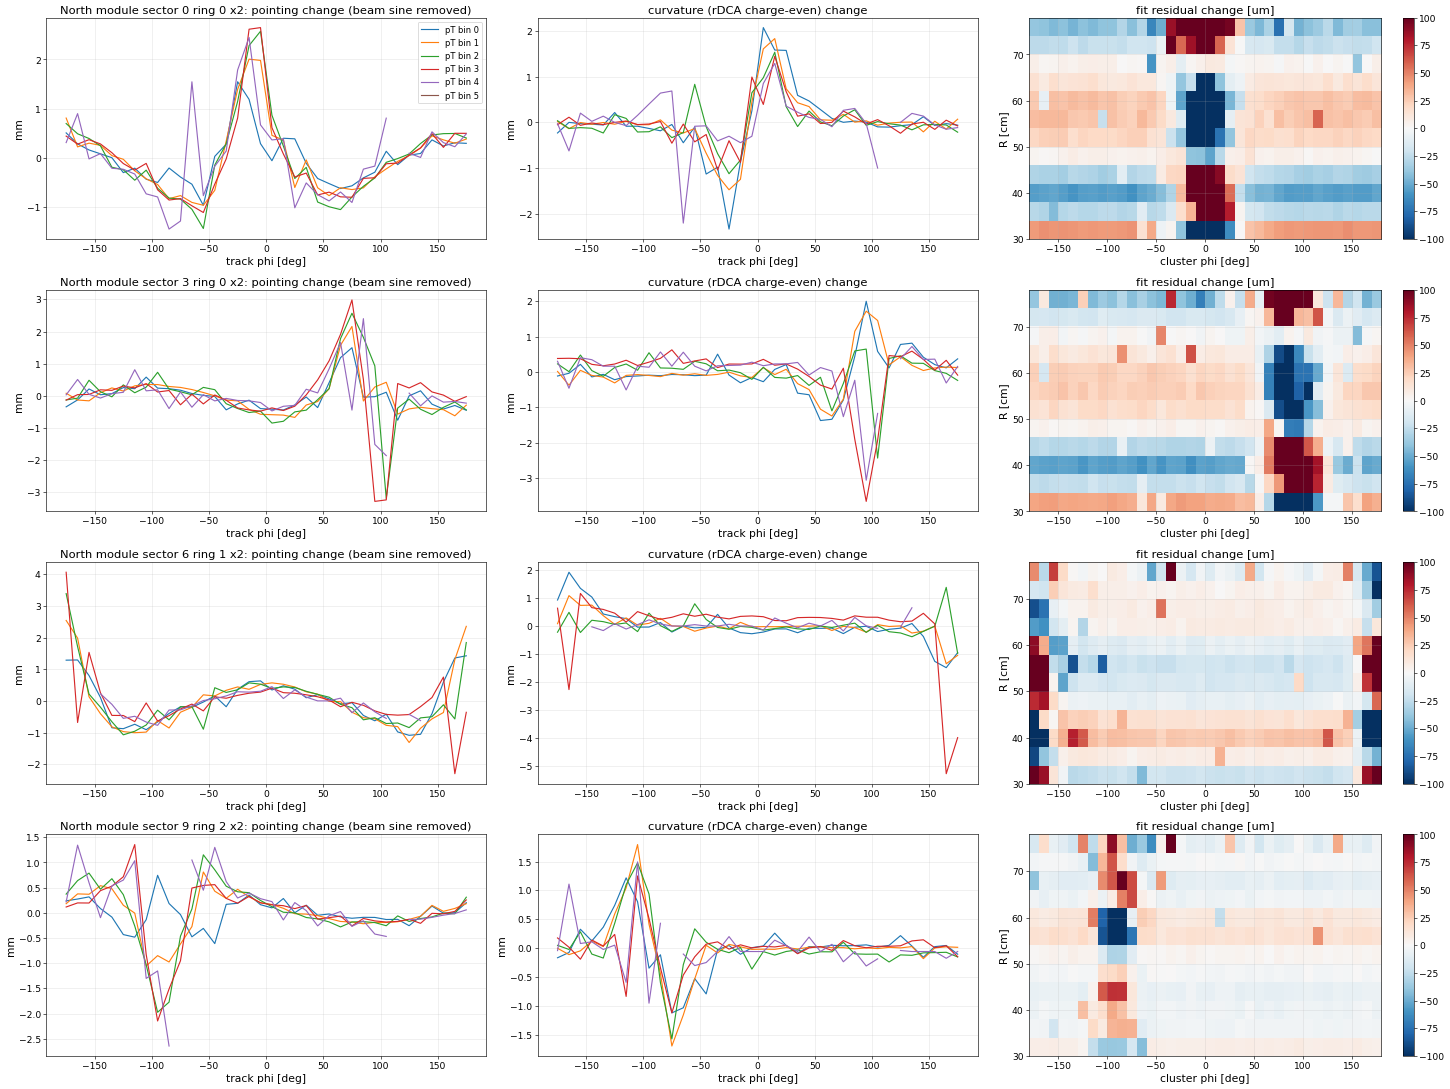

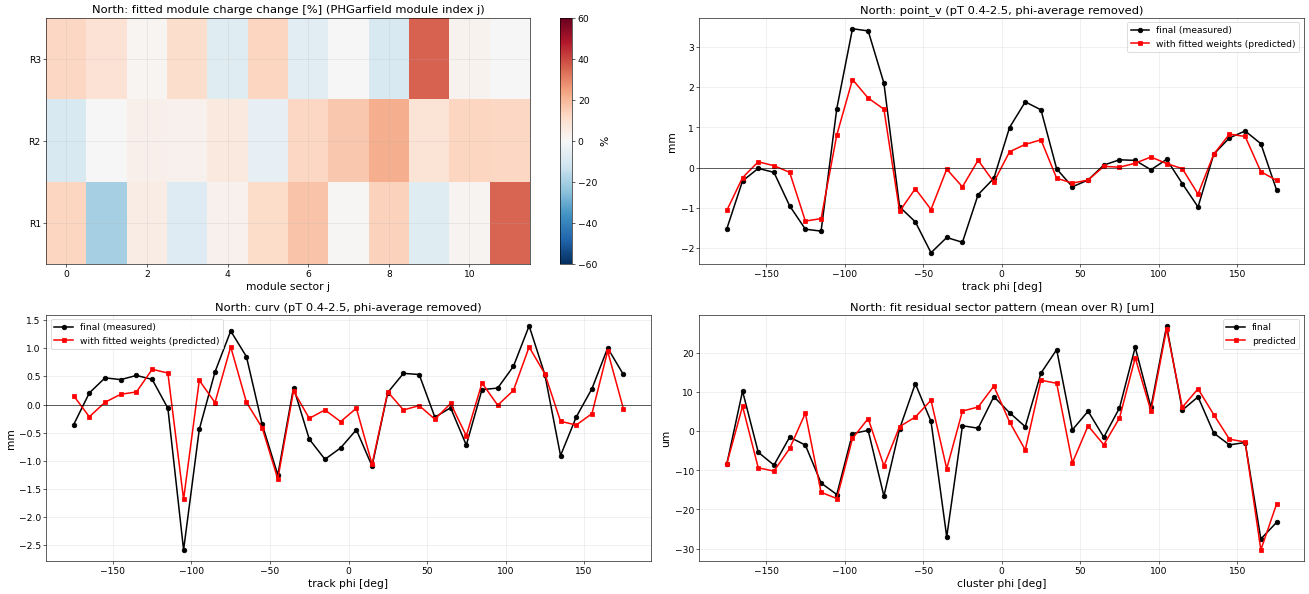

In [24]:
if HAVE_GB:
    for s in (0, 1):
        cc = tg.cross_check(s)
        show(tg.fig_response_examples(s), tg.fig_fit(s, cc[tg.GROUPS]))
else:
    print('gain-basis histograms not there yet')

# Conclusions: how to use the CM to tune PHGarfield

**1. What the CM measures, and how well.** Distortions inside the TPC at the full drift length, per sector and radius, to
≈ 0.1 mrad per module (stripe errors of ~100 µm average out). Propagated with the real cluster positions of a track – φ along the
bend, φ_i = φ0 − q·asin(r_i/2R), and the distortion scaled with the drift length (L − |z|)/L – it predicts how tracks respond to a
PHGarfield change: the φ-averaged pointing (scale ≈ −1, the rDCA sign), its η dependence bin by bin, the curvature
(correlation −0.98 with the high-pT q+/q− ratio) and the φ pattern of module-gain changes. **The CM is quantitatively right for the
distortion inside the TPC.**

**2. What it cannot see.**
* a translation of the TPC relative to the beam: the CM pattern is fixed to the TPC. This is the 2–4 mm pointing harmonic of the tracks
  w.r.t. (0, 0), the same in every pT and η bin, moved by the space-charge correction and different for the two sides by 0.4–0.7 mm;
* the absolute momentum scale: tuned to the CM, final fixes the pointing and the residuals but over-corrects the momentum (high-pT q+/q− 0.90 / 0.94 vs ≈ 1.05
  expected; default 1.06 / 1.21). Pointing (CM) and the high-pT q+/q− ratio prefer different keff (needs ×0.91 / ×0.93 for q+/q−), and every PHGarfield knob moves both
  along the same line;
* sharp sector-edge effects in the curvature (1–2 mm), identical in all configurations.

**3. Gains with tracks (Part D).** One run per module (charge doubled) gives the track response of each module; fitting 36 weights per side
to the φ structure of pointing (rDCA_zero, beam sine removed), curvature and the fit-residual sector map reduces them by 25–30 %
(module changes ±11 %); pointing and curvature fits improve each other, the residual-map fit does not improve the pointing; the R1 weights agree with the CM-fitted (v13) ones (correlation
0.43–0.55 on both sides), R2 / R3 do not (one run cannot separate per-module static from space charge). Validation jobs are prepared
(`trkgain`, `trkgain_half`).

**3b. Frames with tracks.** Raising the frame voltage by +60 V on one side (relative to the final configuration) lowers that side's fit
residuals (South: charge-odd 158 → 128 µm, charge-even 88 → 63 µm; North: 136 → 104 µm, 115 → 96 µm). The other side does not change.
Both sides at +90 V give the lowest charge-odd residual (121 / 95 µm). Beyond +120 V the charge-even residual blows up
(+180 V: 244 µm; +300 V: 410–424 µm). The pointing moves by only +0.1…+0.5 mm and the high-pT q+/q− drops (South 0.90 → 0.79 at +300 V).
So the frame charge is tuned by the residuals, at **≈ +60…+90 V on both sides**, and it does not help the momentum scale.

**4. Recipe.**
1. Fit the PHGarfield maps (level, radial shape, module gains, static knobs) to the CM **propagated to tracks** (Part C model), not to
   the raw dφ(R) profile – that removes the ambiguity of profile R² / pointing numbers dominated by the inner R1 bins.
2. Use several currents (blocks within a fill and across fills) to separate space charge (∝ I) from per-module static.
3. Use tracks for what the CM cannot see: the TPC position relative to the beam / silicon (pointing to the silicon vertex), the absolute
   momentum scale (q+/q− at high pT, K0s), the sector edges.
4. Validate every change with the track jobs (10 segments × 1000 events are enough: φ structure to ~0.1 mm).